**Congo Third ECF Review: Summaries, Indicators and Retrieval**

I worked from IMF Country Report No. 23/271. With `data/` and `cache/` in place, Run all needs no new model calls.

In [1]:
%pip install -q diskcache==5.6.3 faiss-cpu==1.15.1 pypdf==7.0.0   # pinned: the reply cache depends on the exact extracted text

In [2]:
import functools
import hashlib
import itertools
import json
import math
import os
import re
import statistics
import string
import textwrap
import time
import typing
from collections import Counter, defaultdict
from difflib import SequenceMatcher
from pathlib import Path
from typing import Literal, Optional

import attrs
import diskcache
import faiss
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypdf
from scipy import stats
from sentence_transformers import SentenceTransformer

pd.set_option("display.max_colwidth", 120)
print("pypdf", pypdf.__version__, "| faiss", faiss.__version__, "| pandas", pd.__version__, "| attrs", attrs.__version__)

pypdf 7.0.0 | faiss 1.15.1 | pandas 2.2.3 | attrs 26.1.0


**Part 0. Settings**

All the settings are in one place and are printed below.

In [3]:
@attrs.frozen
class Knobs:
    # the document
    pdf: Path = Path("data/IMF_CR_23_271_Republic_of_Congo_Third_ECF_Review.pdf")
    country: str = "Republic of Congo"
    report: str = "IMF Country Report No. 23/271 (July 2023), Third Review under the ECF arrangement"
    # models: a Gemini API key read from a Colab secret
    backend: Literal["gemini_api", "colab_ai", "replay"] = "gemini_api"
    key_secret: str = "GEMINI_FREE_KEY"
    writer: str = "gemini-3.8-flash"
    judge: str = "gemini-3.5-flash-lite"
    writer_temperature: float = 0.2
    judge_temperature: float = 0.0
    max_output_tokens: int = 16384   # the Flash models think before they answer, and thinking counts here
    tries: int = 7
    min_gap_s: float = 1.0           # a short pause between live calls keeps well inside the per-minute limit
    # chunks and retrieval
    embedder: str = "sentence-transformers/all-distilroberta-v1"
    chunk_tokens: int = 470
    overlap_tokens: int = 50
    top_k: int = 5
    keyword_rewrites: int = 3
    bm25_share: float = 0.4          # weight of the BM25 score in the hybrid fusion
    # output rules
    summary_words: tuple = (55, 90)  # the brief's ceiling is 100 words
    bullets: tuple = (5, 7)
    points: tuple = (5, 7)
    # folders
    results: Path = Path("results")
    replies: Path = Path("cache/replies")


K = Knobs()
K.results.mkdir(parents=True, exist_ok=True)
K.replies.parent.mkdir(parents=True, exist_ok=True)
assert K.pdf.exists(), f"put the report at {K.pdf} (it ships in the repository's data/ folder)"
for f in attrs.fields(Knobs):
    print(f"{f.name:20} {getattr(K, f.name)}")

pdf                  data/IMF_CR_23_271_Republic_of_Congo_Third_ECF_Review.pdf
country              Republic of Congo
report               IMF Country Report No. 23/271 (July 2023), Third Review under the ECF arrangement
backend              gemini_api
key_secret           GEMINI_FREE_KEY
writer               gemini-3.8-flash
judge                gemini-3.5-flash-lite
writer_temperature   0.2
judge_temperature    0.0
max_output_tokens    16384
tries                7
min_gap_s            1.0
embedder             sentence-transformers/all-distilroberta-v1
chunk_tokens         470
overlap_tokens       50
top_k                5
keyword_rewrites     3
bm25_share           0.4
summary_words        (55, 90)
bullets              (5, 7)
points               (5, 7)
results              results
replies              cache/replies


**Prompts**

Every prompt is stored by name so the full list can be saved at the end.

In [4]:
class Exact(dict):
    def __missing__(self, key):
        raise KeyError(f"prompt field '{key}' was not supplied")


@attrs.frozen
class PromptCard:
    name: str
    system: str
    user: str

    def fill(self, **fields) -> str:
        return string.Formatter().vformat(self.user, (), Exact(fields))


ECONOMIST = ("You are an economist who reads IMF staff reports closely. Use only the text you are given, "
             "copy numbers exactly as printed, and never add facts from elsewhere.")
CHECKER = ("You check work produced from an IMF staff report against the report's own text. You are strict: "
           "anything not supported by the text counts as a fault.")

CARDS = {c.name: c for c in [
    PromptCard("summarise", ECONOMIST,
               "Summarise the part of the IMF report titled \"{title}\" (PDF pages {pages}) in {low} to {high} words. "
               "Keep the figures that matter, copied as printed, and state the part's main judgement or recommendation. "
               "Write plain prose with no list and no heading.{note}\n\nTEXT:\n{text}"),
    PromptCard("judge_summary", CHECKER,
               "SOURCE (\"{title}\"):\n{text}\n\nSUMMARY:\n{summary}\n\n"
               "Score the summary from 1 (poor) to 5 (exact) on consistency (it never contradicts the source), "
               "completeness (the main points of this part are present) and factual_alignment (every figure and "
               "claim can be found in the source). List each concrete fault in faults; an empty list means none."),
    PromptCard("bullets", ECONOMIST,
               "Below are summaries of the sections of the report, each with an id. Write {low} to {high} executive "
               "summary bullets for a finance ministry reader. Each bullet is one sentence of at most 35 words and "
               "gives the id of the section it rests on. Between them the bullets must cover growth and inflation, "
               "fiscal policy, public debt, banking soundness, how the program performed, and the main risks.{note}\n\n{summaries}"),
    PromptCard("judge_bullets", CHECKER,
               "Check each numbered BULLET against the section summary whose id it cites. For each give supported "
               "(true or false) and a short reason. Then score the set from 1 to 5 on consistency, completeness "
               "(does it cover the report's main messages?) and factual_alignment, and list faults.\n\n"
               "BULLETS:\n{bullets}\n\nSUMMARIES:\n{summaries}"),
    PromptCard("themes", ECONOMIST,
               "Give each passage below the one theme it is mostly about (primary) and any other themes it also "
               "discusses (others). Allowed themes: {themes}. Use \"none\" as primary if no theme fits. Return one "
               "label per passage id.\n\n{passages}"),
    PromptCard("points", ECONOMIST,
               "From the staff report text below, list {low} to {high} strengths and {low} to {high} vulnerabilities "
               "of the {country} economy as IMF staff see them. For each give a short label (at most 8 words), a "
               "one-sentence explanation, the pdf_page, and a quote of 8 to 30 words copied exactly from that page. "
               "Pages are marked [p.N].\n\nTEXT:\n{text}"),
    PromptCard("judge_points", CHECKER,
               "For each numbered POINT, say whether its quote supports the label and explanation (supported) and "
               "whether it is rightly classed as a strength or a vulnerability (correct_class), with a short reason."
               "\n\n{points}"),
    PromptCard("indicators", ECONOMIST,
               "Fill the indicator record for {country} from the pages below. For each field use the most recent "
               "figure the report gives for the report year or the year ahead; in Table 1 that is the column marked "
               "2023 Proj., not the older CR 23/89 vintage. Give value, year, pdf_page, source (the table row label or "
               "the sentence the figure comes from) and reason. If the report gives no figure for a field, set value, "
               "year and pdf_page to null and say why in reason. Never compute or estimate a figure.\n\n"
               "FIELDS:\n{fields}\n\nPAGES:\n{pages}"),
    PromptCard("audit_indicators", CHECKER,
               "Each ITEM is a figure another model took from the report. Look at its cited page and give a verdict: "
               "CORRECT (the page shows this value for this field and year), WRONG (the page shows a different value; "
               "give it in page_shows), NOT_FOUND (the page has no such figure), CORRECTLY_NULL (the report has no "
               "figure and null is right) or MISSED (null was given but the pages do show a figure; give it). "
               "Add a short reason.\n\nITEMS:\n{items}\n\nPAGES:\n{pages}"),
    PromptCard("series", ECONOMIST,
               "From the table below copy every value of these rows: {rows}. The columns, in order, are: {columns}. "
               "Use null for an empty cell or one that shows ... and copy numbers exactly.\n\n"
               "TABLE (PDF page {page}):\n{table}"),
    PromptCard("answer", ECONOMIST,
               "QUESTION: {question}\n\nAnswer from the numbered passages only, in at most 80 words, and cite the "
               "passage ids you used in square brackets, for example [C12]. If the passages do not hold the answer, "
               "say so plainly, cite nothing and set answerable to false.\n\nPASSAGES:\n{passages}"),
    PromptCard("judge_answer", CHECKER,
               "QUESTION: {question}\n\nANSWER:\n{answer}\n\nPASSAGES:\n{passages}\n\nScore faithfulness from 1 to 5 "
               "(every claim in the answer is backed by the passages) and completeness from 1 to 5 (the answer gives "
               "what the passages say about the question; a plain refusal is complete when the passages do not answer "
               "it). Give one sentence of reason for each score."),
    PromptCard("probes", ECONOMIST,
               "QUESTION: {question}\n\nDo not answer the question. Write one step-back question about the broader "
               "topic behind it (step_back), and {n} short keyword search queries of 4 to 8 words that use the terms an "
               "IMF staff report would use (keywords)."),
]}
print(len(CARDS), "prompt cards:", ", ".join(CARDS))

13 prompt cards: summarise, judge_summary, bullets, judge_bullets, themes, points, judge_points, indicators, audit_indicators, series, answer, judge_answer, probes


**Reply shapes**

Each model reply has a fixed shape, so a wrong or incomplete reply is caught.

In [5]:
class ShapeError(ValueError):
    """A reply that does not fit its class."""


def score():
    return attrs.field(validator=attrs.validators.in_(range(1, 6)), metadata={"schema": {"minimum": 1, "maximum": 5}})


def schema_for(tp) -> dict:
    if attrs.has(tp):
        props = {}
        for f in attrs.fields(tp):
            props[f.name] = {**schema_for(f.type), **f.metadata.get("schema", {})}
        return {"type": "object", "properties": props, "required": list(props)}
    origin, args = typing.get_origin(tp), typing.get_args(tp)
    if origin is typing.Union:
        inner = [a for a in args if a is not type(None)]
        return {"anyOf": [schema_for(inner[0]), {"type": "null"}]}
    if origin is list:
        return {"type": "array", "items": schema_for(args[0])}
    if origin is Literal:
        return {"type": "string", "enum": list(args)}
    return {"type": {str: "string", int: "integer", float: "number", bool: "boolean"}[tp]}


def from_json(tp, value, where="reply"):
    if attrs.has(tp):
        if not isinstance(value, dict):
            raise ShapeError(f"{where}: expected an object")
        names = [f.name for f in attrs.fields(tp)]
        extra, missing = set(value) - set(names), [n for n in names if n not in value]
        if extra or missing:
            raise ShapeError(f"{where}: unknown keys {sorted(extra)}, missing keys {missing}")
        types_ = {f.name: f.type for f in attrs.fields(tp)}
        try:
            return tp(**{n: from_json(types_[n], value[n], f"{where}.{n}") for n in names})
        except (ValueError, TypeError) as err:
            raise ShapeError(f"{where}: {err}") from None
    origin, args = typing.get_origin(tp), typing.get_args(tp)
    if origin is typing.Union:
        return None if value is None else from_json(args[0], value, where)
    if origin is list:
        if not isinstance(value, list):
            raise ShapeError(f"{where}: expected a list")
        return [from_json(args[0], v, f"{where}[{i}]") for i, v in enumerate(value)]
    if origin is Literal:
        if value not in args:
            raise ShapeError(f"{where}: {value!r} is not one of {args}")
        return value
    if tp is float and isinstance(value, (int, float)) and not isinstance(value, bool):
        return float(value)
    if tp is int and isinstance(value, float) and value.is_integer():
        return int(value)
    if isinstance(value, tp) and not (tp is int and isinstance(value, bool)):
        return value
    raise ShapeError(f"{where}: expected {tp.__name__}, got {type(value).__name__}")


@attrs.frozen
class SummaryReply:
    summary: str


@attrs.frozen
class Verdict:
    consistency: int = score()
    completeness: int = score()
    factual_alignment: int = score()
    faults: list[str] = attrs.field(factory=list)

    @property
    def total(self) -> int:
        return self.consistency + self.completeness + self.factual_alignment


@attrs.frozen
class Bullet:
    section_id: str
    text: str


@attrs.frozen
class BulletsReply:
    bullets: list[Bullet]


@attrs.frozen
class BulletCheck:
    number: int
    supported: bool
    reason: str


@attrs.frozen
class BulletVerdict:
    checks: list[BulletCheck]
    consistency: int = score()
    completeness: int = score()
    factual_alignment: int = score()
    faults: list[str] = attrs.field(factory=list)


@attrs.frozen
class ThemeLabel:
    chunk_id: str
    primary: str
    others: list[str]


@attrs.frozen
class ThemeReply:
    labels: list[ThemeLabel]


@attrs.frozen
class Point:
    label: str
    explanation: str
    pdf_page: int
    quote: str


@attrs.frozen
class PointsReply:
    strengths: list[Point]
    vulnerabilities: list[Point]


@attrs.frozen
class PointCheck:
    number: int
    supported: bool
    correct_class: bool
    reason: str


@attrs.frozen
class PointVerdict:
    checks: list[PointCheck]


@attrs.frozen
class Figure:
    value: Optional[float]
    year: Optional[int]
    pdf_page: Optional[int]
    source: Optional[str]
    reason: str


INDICATOR_FIELDS = ("gdp_growth_forecast_pct", "headline_inflation_rate_pct", "central_bank_policy_rate_pct",
                    "non_performing_loan_ratio", "unemployment_rate_pct", "tier_1_capital_ratio")
IndicatorReply = attrs.make_class("IndicatorReply", {f: attrs.field(type=Figure) for f in INDICATOR_FIELDS}, frozen=True)


@attrs.frozen
class AuditItem:
    field: str
    verdict: Literal["CORRECT", "WRONG", "NOT_FOUND", "CORRECTLY_NULL", "MISSED"]
    page_shows: Optional[float]
    reason: str


@attrs.frozen
class AuditReply:
    items: list[AuditItem]


@attrs.frozen
class SeriesRow:
    label: str
    values: list[Optional[float]]


@attrs.frozen
class SeriesReply:
    rows: list[SeriesRow]


@attrs.frozen
class AnswerReply:
    answer: str
    citations: list[str]
    answerable: bool


@attrs.frozen
class AnswerVerdict:
    faithfulness: int = score()
    completeness: int = score()
    faithfulness_reason: str = ""
    completeness_reason: str = ""


@attrs.frozen
class Probes:
    step_back: str
    keywords: list[str]


print(json.dumps(schema_for(Verdict)))

{"type": "object", "properties": {"consistency": {"type": "integer", "minimum": 1, "maximum": 5}, "completeness": {"type": "integer", "minimum": 1, "maximum": 5}, "factual_alignment": {"type": "integer", "minimum": 1, "maximum": 5}, "faults": {"type": "array", "items": {"type": "string"}}}, "required": ["consistency", "completeness", "factual_alignment", "faults"]}


**Model calls**

All calls go through `consult()`. Replies are saved, failed calls are retried, and a bad reply gets one repair.

In [6]:
class NoBackend(RuntimeError):
    """A reply is needed, but there is no stored copy and no model to ask."""


def read_key() -> Optional[str]:
    try:
        from google.colab import userdata
    except ImportError:
        return os.environ.get(K.key_secret)
    try:
        return userdata.get(K.key_secret)
    except Exception as err:          # secret missing, or notebook access not granted
        print(f"Colab secret {K.key_secret} could not be read ({type(err).__name__}); stored replies only")
        return None


def pick_backend() -> str:
    if K.backend == "gemini_api":
        return "gemini_api" if read_key() else "replay"
    if K.backend == "colab_ai":
        try:
            from google.colab import ai  # noqa: F401
            return "colab_ai"
        except ImportError:
            return "replay"
    return "replay"


BACKEND = pick_backend()
REPLIES = diskcache.Cache(str(K.replies), sqlite_journal_mode="delete")
CALLS: list[dict] = []
_live = {"client": None, "last": 0.0}


def live_call(model: str, system: str, prompt: str, schema: dict, temperature: float) -> dict:
    gap = K.min_gap_s - (time.monotonic() - _live["last"])
    if gap > 0:
        time.sleep(gap)
    _live["last"] = time.monotonic()
    t0 = time.perf_counter()
    if BACKEND == "gemini_api":
        from google import genai
        from google.genai import types
        if _live["client"] is None:
            _live["client"] = genai.Client(api_key=read_key())
        resp = _live["client"].models.generate_content(
            model=model, contents=prompt,
            config=types.GenerateContentConfig(system_instruction=system, temperature=temperature,
                                               max_output_tokens=K.max_output_tokens,
                                               response_mime_type="application/json", response_json_schema=schema))
        if resp.candidates and "MAX_TOKENS" in str(resp.candidates[0].finish_reason):
            raise RuntimeError("the reply was cut off at max_output_tokens")
        meta = resp.usage_metadata
        text, t_in, t_out = resp.text or "", meta.prompt_token_count or 0, meta.candidates_token_count or 0
    elif BACKEND == "colab_ai":
        from google.colab import ai
        from openai import OpenAI
        if _live["client"] is None:
            _live["client"] = OpenAI(base_url=f"{ai._get_model_proxy_host()}/models/openapi",
                                     api_key=ai._get_model_proxy_token())
        shaped = f"{prompt}\n\nReply with a single JSON object that follows this JSON Schema:\n{json.dumps(schema)}"
        resp = _live["client"].chat.completions.create(
            model=f"google/{model}", temperature=temperature, max_tokens=K.max_output_tokens,
            messages=[{"role": "system", "content": system}, {"role": "user", "content": shaped}])
        text = resp.choices[0].message.content or ""
        t_in, t_out = (resp.usage.prompt_tokens, resp.usage.completion_tokens) if resp.usage else (0, 0)
    else:
        raise NoBackend(f"no stored reply for this prompt; add the Colab secret {K.key_secret} to make new calls")
    return {"text": text, "seconds": round(time.perf_counter() - t0, 2), "tokens_in": int(t_in), "tokens_out": int(t_out)}


HOPELESS = re.compile(r"PerDay|prepay|billing|exceeds available quota|API key not valid|PERMISSION_DENIED", re.I)


def asked_delay(err: Exception) -> Optional[float]:
    found = re.search(r"retry(?:Delay)?['\": ]+(?:in )?([\d.]+)s", str(err))
    return float(found.group(1)) + 1 if found else None


def stored_or_live(step: str, role: str, system: str, prompt: str, schema: dict) -> dict:
    model = K.writer if role == "writer" else K.judge
    temperature = K.writer_temperature if role == "writer" else K.judge_temperature
    key = hashlib.sha3_256(json.dumps([model, system, prompt, schema, temperature], sort_keys=True).encode()).hexdigest()
    record, origin = REPLIES.get(key), "stored"
    if record is None:
        origin = "live"
        for attempt in range(1, K.tries + 1):
            try:
                record = live_call(model, system, prompt, schema, temperature)
                if record["text"].strip():
                    break
                raise RuntimeError("empty reply")
            except NoBackend:
                raise
            except Exception as err:
                if attempt == K.tries or HOPELESS.search(str(err)):
                    raise
                pause = min(120.0, asked_delay(err) or 8.0 * attempt)
                print(f"  {step}: {type(err).__name__}: {str(err)[:90]} | try {attempt + 1} in {pause:.0f}s")
                time.sleep(pause)
        REPLIES[key] = record
    CALLS.append({"step": step, "role": role, "model": model, "origin": origin, "seconds": record["seconds"],
                  "tokens_in": record["tokens_in"], "tokens_out": record["tokens_out"], "repair": step.endswith("+fix")})
    return record


def json_in(text: str):
    start = text.find("{")
    if start < 0:
        raise ShapeError("the reply holds no JSON object")
    try:
        return json.JSONDecoder().raw_decode(text[start:])[0]
    except json.JSONDecodeError as err:
        raise ShapeError(f"the reply is not valid JSON ({err.msg})") from None


def consult(step: str, role: Literal["writer", "judge"], card: str, shape, check=None, **fields):
    """Fill a card, get the reply (stored or live), shape it, check it, and allow one repair."""
    system, prompt = CARDS[card].system, CARDS[card].fill(**fields)
    schema = schema_for(shape)
    record = stored_or_live(step, role, system, prompt, schema)
    for round_ in ("first", "repair"):
        try:
            reply = from_json(shape, json_in(record["text"]))
            problems = list(check(reply)) if check else []
        except ShapeError as err:
            reply, problems = None, [str(err)[:300]]
        if not problems:
            return reply
        if round_ == "repair":
            raise RuntimeError(f"{step}: the repaired reply still fails: {problems[:3]}")
        print(f"  {step}: one repair round ({problems[0][:100]})")
        fix = (f"{prompt}\n\nYour last reply broke these rules:\n- " + "\n- ".join(problems[:10]) +
               f"\n\nYour last reply was:\n{record['text'][:3500]}\n\nSend the corrected JSON only.")
        record = stored_or_live(step + "+fix", role, system, fix, schema)


@functools.singledispatch
def plain(obj):
    """Turn results into JSON-ready values."""
    if attrs.has(type(obj)):
        return {k: plain(v) for k, v in attrs.asdict(obj, recurse=False).items()}
    if isinstance(obj, (np.integer, np.floating)):
        return obj.item()
    if isinstance(obj, float) and math.isnan(obj):
        return None
    return obj


@plain.register(dict)
def _(obj):
    return {str(k): plain(v) for k, v in obj.items()}


@plain.register(list)
@plain.register(tuple)
def _(obj):
    return [plain(v) for v in obj]


@plain.register(pd.DataFrame)
def _(obj):
    return plain(obj.astype(object).where(obj.notna(), None).to_dict("records"))


def keep(name: str, obj) -> Path:
    path = K.results / f"{name}.json"
    path.write_text(json.dumps(plain(obj), indent=2, ensure_ascii=False), encoding="utf-8")
    return path


print(f"backend: {BACKEND} | writer {K.writer} | judge {K.judge} | stored replies: {len(REPLIES)}")

backend: gemini_api | writer gemini-3.8-flash | judge gemini-3.5-flash-lite | stored replies: 159


**Part 1. Read the pages**

I read each page with pypdf and keep its PDF page number.

In [7]:
@attrs.define
class Leaf:
    pdf_page: int
    raw: str
    clean: str = ""


reader = pypdf.PdfReader(K.pdf)
LEAVES = [Leaf(n, page.extract_text() or "") for n, page in enumerate(reader.pages, start=1)]
empty = [leaf.pdf_page for leaf in LEAVES if len(leaf.raw.strip()) < 40]
print(f"{len(LEAVES)} pages, {sum(len(l.raw) for l in LEAVES):,} characters; pages with almost no text: {empty or 'none'}")
print(textwrap.indent(LEAVES[28].raw[:700], "  | "))

130 pages, 395,624 characters; pages with almost no text: none
  | REPUBLIC OF CONGO 
  | 26 INTERNATIONAL MONETARY FUND  
  | Table 1. Republic of Congo: Selected Economic and Financial Indicators, 2022–28 1 
  
 
  | 2022 2022 2023 2023 2024 2025 2026 2027 2028
  | C
  | R 23/89 Prel. CR 23/89
  |  Production and prices
  | GDP at constant prices 2.8 1 .7 4.1 4.0 4.4 3.3 3.8 3.9 4.0
  | Oil 0.5 - 3.8 4.4 4.4 6.5 -0.3 -0.2 0.0 -0.1
  | Non-oil 3.3 3 .3 4.0 3.9 3.8 4.3 4.8 4.8 4.8
  | GDP at current prices 16.4 17. 1 4.1 -0.7 5.5 4.9 5.7 6.0 6.2
  | GDP deflator 13.2 15. 1 0.0 -4.5 1.0 1.6 1.8 2.0 2.2
  | Non-oil 3.6 3 .1 3.3 3.5 3.2 3.0 3.0 3.0 3.0
  | Consumer prices (period average) 3.5 3 .0 3.3 3.5 3.2 3.0 3.0 3.0 3.0
  | Consumer prices (end of period) 3.5 3 .2 3.3 3.5 3.2 3.0 3.0 3.0 3.0
  |  External sector
 


**Clean the text**

This removes running heads and repairs split numbers and broken words.

In [8]:
DASH = "\u2013"
NUMBER = re.compile(r"-?\d[\d,]*\.?\d*")
HEADS = [re.compile(r"^REPUBLIC OF CONGO$"), re.compile(r"^\d{1,3}\s+INTERNATIONAL MONETARY FUND$"),
         re.compile(r"^INTERNATIONAL MONETARY FUND\s+\d{1,3}$")]


def tableish(line: str) -> bool:
    return len(NUMBER.findall(line)) >= 3


def drop_heads(text):
    lines = [l.rstrip() for l in text.split("\n")]
    stripped = [l.strip() for l in lines]
    filled = [i for i, s in enumerate(stripped) if s]
    edge = set(filled[:2] + filled[-2:])
    keep_, n = [], 0
    for i, (line, s) in enumerate(zip(lines, stripped)):
        if any(h.match(s) for h in HEADS) or (i in edge and re.fullmatch(r"\d{1,3}", s)):
            n += 1
            continue
        keep_.append(line)
    return "\n".join(keep_), n


def per_line(pattern, repl, where=lambda line: True):
    rx = re.compile(pattern)

    def rule(text):
        out, n = [], 0
        for line in text.split("\n"):
            if where(line):
                line, k = rx.subn(repl, line)
                n += k
            out.append(line)
        return "\n".join(out), n
    return rule


RULES = {
    "running heads": drop_heads,
    "repeated spaces": per_line(r"(?<=\S) {2,}(?=\S)", " "),
    "space before decimal point": per_line(r"(?<=\d) \.(?=\d)", "."),
    "space after decimal point (tables)": per_line(r"(?<=\d)\. (?=\d)", ".", tableish),
    "space after decimal point (prose)": per_line(r"(?<=\b\d)\. (?=\d percent)", "."),
    "space after thousands comma": per_line(r"(?<=\d), (?=\d{3}\b)", ",", tableish),
    "detached minus sign": per_line(r"(?<![\w)]) ?- (?=\d)", " -", tableish),
    "split year": per_line(r"\b(20\d) (\d)(?= ?" + DASH + ")", r"\1\2"),
    "split century": per_line(r"\b20 (\d\d)(?= ?" + DASH + ")", r"20\1"),
    "spaced range dash": per_line(r"(?<=\d) ?" + DASH + r" ?(?=\d)", DASH),
    "hyphen then space": per_line(r"(?<=[a-z])- (?=[a-z])", "-"),
    "hyphen at line end": lambda text: re.subn(r"(?<=[a-z])- *\n(?=[a-z])", "-", text),
    "space before punctuation": per_line(r"(?<=\S) +(?=[,.;:)\]])", "", lambda l: not tableish(l)),
    "space after bracket": per_line(r"(?<=[(\[]) +", "", lambda l: not tableish(l)),
    "split report number": per_line(r"(?<=CR )(\d) (\d)(?=/)", r"\1\2"),
}

VOCAB = Counter(w.lower() for leaf in LEAVES for w in re.findall(r"[A-Za-z]+", leaf.raw))


def mend_words(text):
    """Join fragments such as 'expe cted' or 'Stra teg y' when the joined word is a known word of the report."""
    n, out = 0, []
    for line in text.split("\n"):
        toks, i, mended = line.split(" "), 0, []
        while i < len(toks):
            for width in (3, 2):
                group = toks[i:i + width]
                tail = re.match(r"[A-Za-z]+", group[-1]) if len(group) == width else None
                if not tail or not all(re.fullmatch(r"[A-Za-z]+", t) for t in group[:-1]):
                    continue
                frags = group[:-1] + [tail.group(0)]
                core = "".join(frags)
                if VOCAB[core.lower()] >= 2 and any(VOCAB[f.lower()] <= 2 for f in frags):
                    JOINED[" ".join(frags) + " > " + core] += 1
                    mended.append(core + group[-1][tail.end():])
                    i, n = i + width, n + width - 1
                    break
            else:
                mended.append(toks[i])
                i += 1
        out.append(" ".join(mended))
    return "\n".join(out), n


RULES["broken words"] = mend_words
FIRED, JOINED = Counter(), Counter()


def clean_page(text: str) -> str:
    def step(acc, item):
        name, rule = item
        acc, n = rule(acc)
        FIRED[name] += n
        return acc
    return functools.reduce(step, RULES.items(), text)


for leaf in LEAVES:
    leaf.clean = clean_page(leaf.raw)
print("broken words joined, most frequent first:", "; ".join(k for k, _ in JOINED.most_common(14)))

pd.DataFrame(sorted(FIRED.items(), key=lambda kv: -kv[1]), columns=["rule", "changes"])

broken words joined, most frequent first: wi ll > will; pric es > prices; procedure s > procedures; prog ram > program; corrup tion > corruption; w ith > with; Op erations > Operations; Co untry > Country; E ngagement > Engagement; Stra teg y > Strategy; ris ing > rising; cas h > cash; bas is > basis; Ad verse > Adverse


,rule,changes
0,repeated spaces,882
1,running heads,251
2,space before punctuation,225
3,broken words,202
4,spaced range dash,92
5,space after decimal point (tables),47
6,space before decimal point,44
7,detached minus sign,27
8,hyphen at line end,19
9,space after bracket,16


**Spot checks**

Three lines are checked against the PDF.

In [9]:
def find_line(page: int, start: str) -> str:
    return next(l.strip() for l in LEAVES[page - 1].clean.split("\n") if start in l)


for page, start in [(29, "GDP at constant prices"), (29, "GDP at current prices"), (11, "Inflation is expected")]:
    print(f"p.{page}: {find_line(page, start)}")
print("p.49:", next(l for l in LEAVES[48].clean.split("\n") if l.startswith("Annex I.")))
assert find_line(29, "GDP at constant prices").endswith("2.8 1.7 4.1 4.0 4.4 3.3 3.8 3.9 4.0")
assert "average 3.5 percent" in find_line(11, "Inflation is expected")

p.29: GDP at constant prices 2.8 1.7 4.1 4.0 4.4 3.3 3.8 3.9 4.0
p.29: GDP at current prices 16.4 17.1 4.1 -0.7 5.5 4.9 5.7 6.0 6.2
p.11: • Inflation is expected to average 3.5 percent in 2023. Upward price pressures from fuel price
p.49: Annex I. Country Engagement Strategy1


**Find the sections**

Headings are found from the contents page, and other parts by their titles.

In [10]:
@attrs.define
class Section:
    sid: str
    title: str
    first: int                   # PDF page of the heading
    line: int                    # line of the heading on that page
    last: int = 0
    text: str = ""               # clean text with [p.N] page marks
    summarise: bool = True


def squash(s: str) -> str:
    return re.sub(r"[^A-Z0-9]", "", s.upper())


contents = LEAVES[5].clean.split("\n")
listed = []
for line in contents[contents.index(next(l for l in contents if l.strip() == "CONTENTS")) + 1:]:
    if line.strip() == "BOXES":
        break
    m = re.match(r"^(.*?)\s*_{3,}\s*(\d+)\s*$", line.strip())
    if m:
        listed.append(m.group(1).strip())
print("listed in CONTENTS:", listed)


def locate(title, test, after=(1, -1)):
    """First line after `after` that passes `test`, alone or joined with the next line (headings can wrap)."""
    for leaf in LEAVES[after[0] - 1:]:
        lines = [l.strip() for l in leaf.clean.split("\n")] + [""]
        for i, (line, nxt) in enumerate(zip(lines, lines[1:])):
            if (leaf.pdf_page, i) > after and line and (test(line) or test(f"{line} {nxt}")):
                return leaf.pdf_page, i
    raise LookupError(f"heading not found: {title}")


def fuzzy(title):
    return lambda line: 0 < len(line) < 90 and SequenceMatcher(None, squash(line), squash(title)).ratio() >= 0.9


OUTLINE = ([("Cover", lambda l: l.startswith("IMF Country Report No."), False),
            ("Press release", lambda l: l.startswith("PR 23/270"), True),
            ("Executive summary", lambda l: l == "EXECUTIVE SUMMARY", True),
            ("Mission, contents and lists", lambda l: l == "Approved By", False)]
           + [(t.title() if t.isupper() else t, fuzzy(t), True) for t in listed]
           + [("Figures and statistical tables", lambda l: l.startswith("Figure 1. Republic of Congo"), True),
              ("Annex I. Country engagement strategy", lambda l: l.startswith("Annex I. Country"), True),
              ("Annex II. Risk assessment matrix", lambda l: l.startswith("Annex II. Risk"), True),
              ("Appendix I. Letter of intent", lambda l: l.startswith("Appendix I. Letter of Intent"), True),
              ("Attachment I. Memorandum of economic and financial policies", lambda l: l.startswith("Attachment I. Memorandum"), True),
              ("Attachment II. Technical memorandum of understanding", lambda l: l.startswith("Attachment II. Technical"), True),
              ("Debt sustainability analysis", lambda l: l.startswith("Republic of Congo: Joint Bank"), True),
              ("Staff supplement", lambda l: "SUPPLEMENTARY INFORMATION" in l.replace("\u2014", " "), True),
              ("Executive Director's statement", lambda l: l.startswith("Statement by Mr."), True)])

SECTIONS, at = [], (1, -1)
for title, test, summarise in OUTLINE:
    page, line = locate(title, test, at)
    SECTIONS.append(Section(f"S{len(SECTIONS):02d}", title, page, line, summarise=summarise))
    at = (page, line)

for sec, nxt in zip(SECTIONS, SECTIONS[1:] + [None]):
    end = (nxt.first, nxt.line) if nxt else (len(LEAVES) + 1, 0)
    parts = []
    for leaf in LEAVES[sec.first - 1:end[0]]:
        lines = leaf.clean.split("\n")
        lo = sec.line if leaf.pdf_page == sec.first else 0
        hi = end[1] if leaf.pdf_page == end[0] else len(lines)
        body = "\n".join(lines[lo:hi]).strip()
        if body:
            parts.append(f"[p.{leaf.pdf_page}] {body}")
            sec.last = leaf.pdf_page
    sec.text = "\n".join(parts)

# a heading that is followed at once by its first subsection carries no text of its own
for sec, nxt in zip(SECTIONS, SECTIONS[1:]):
    if sec.summarise and len(sec.text.split()) < 150:
        nxt.text, nxt.first, nxt.title = sec.text + "\n" + nxt.text, sec.first, f"{sec.title}: {nxt.title}"
        sec.summarise, sec.text = False, ""
SECTIONS = [s for s in SECTIONS if s.text]
for n, s in enumerate(SECTIONS):
    s.sid = f"S{n:02d}"

outline = pd.DataFrame([{"id": s.sid, "title": s.title, "pages": f"{s.first}-{s.last}", "words": len(s.text.split()),
                         "summarised": s.summarise} for s in SECTIONS])
print(f"{len(SECTIONS)} sections, {int(outline.summarised.sum())} to summarise")
outline

listed in CONTENTS: ['CONTEXT', 'RECENT ECONOMIC DEVELOPMENTS, OUTLOOK, AND RISKS', 'PROGRAM PERFORMANCE', 'POLICY DISCUSSIONS', 'A. Fiscal Policy', 'B. Public Investment and Debt Management', 'C. Governance, Transparency, and Broader Structural Reforms', 'PROGRAM MODALITIES AND OTHER ISSUES', 'STAFF APPRAISAL']
21 sections, 19 to summarise


,id,title,pages,words,summarised
0,S00,Cover,1-1,258,False
1,S01,Press release,2-4,824,True
2,S02,Executive summary,4-5,396,True
3,S03,"Mission, contents and lists",6-7,462,False
4,S04,Context,8-8,366,True
5,S05,"Recent Economic Developments, Outlook, And Risks",8-12,1434,True
6,S06,Program Performance,12-13,507,True
7,S07,Policy Discussions: A. Fiscal Policy,13-17,2071,True
8,S08,B. Public Investment and Debt Management,17-18,973,True
9,S09,"C. Governance, Transparency, and Broader Structural Reforms",19-21,1016,True


**Make chunks**

Chunks are up to 470 tokens with an overlap of 50, and they stay inside one section.

In [11]:
ENCODER = SentenceTransformer(K.embedder)
TOK = ENCODER.tokenizer
TOK.model_max_length = 10**6     # the tokenizer is also used to count tokens of whole paragraphs; the encoder still reads at most 512


@attrs.frozen
class Chunk:
    cid: str
    sid: str
    pages: tuple
    text: str
    tokens: int


def ids_of(text: str) -> list[int]:
    return TOK(" " + text, add_special_tokens=False)["input_ids"]


def pieces(section: Section):
    """(page, token ids) for each paragraph of a section, long paragraphs cut into sentences or windows."""
    room = K.chunk_tokens - K.overlap_tokens
    for block in re.split(r"(?=\[p\.\d+\] )", section.text):
        m = re.match(r"\[p\.(\d+)\] ", block)
        if not m:
            continue
        page = int(m.group(1))
        for para in re.split(r"\n(?=\s*(?:\u2022|\d{1,2}\. [A-Z]|[A-Z][A-Z ,\-]{8,}$))|\n\s*\n", block[m.end():]):
            para = " ".join(para.split())
            if not para:
                continue
            ids = ids_of(para)
            if len(ids) <= room:
                yield page, ids
                continue
            for sent in re.split(r"(?<=[.;!?])\s+(?=[A-Z(\u2022])", para):
                ids = ids_of(sent)
                for at_ in range(0, len(ids), room):
                    yield page, ids[at_:at_ + room]


def word_tail(ids: list[int]) -> list[int]:
    tail = ids[-K.overlap_tokens:]
    marks = TOK.convert_ids_to_tokens(tail)
    start = next((i for i, t in enumerate(marks) if t.startswith("\u0120")), 0)
    return tail[start:]


CHUNKS = []
for sec in SECTIONS:
    buf, pages_ = [], []
    for page, ids in pieces(sec):
        if buf and len(buf) + len(ids) > K.chunk_tokens:
            CHUNKS.append((sec.sid, tuple(sorted(set(pages_))), buf))
            buf, pages_ = word_tail(buf), [pages_[-1]]
        buf, pages_ = buf + ids, pages_ + [page]
    if buf:
        CHUNKS.append((sec.sid, tuple(sorted(set(pages_))), buf))
CHUNKS = [Chunk(f"C{n:03d}", sid, pages_, TOK.decode(ids).strip(), len(ids)) for n, (sid, pages_, ids) in enumerate(CHUNKS)]

recount = [len(TOK(c.text, add_special_tokens=False)["input_ids"]) for c in CHUNKS]
sizes = pd.Series([c.tokens for c in CHUNKS])
print(f"{len(CHUNKS)} chunks | tokens min {sizes.min()}, median {sizes.median():.0f}, max {sizes.max()} "
      f"| re-encoded max {max(recount)}")
assert sizes.max() <= K.chunk_tokens and max(recount) <= K.chunk_tokens + 5
keep("sections", [{"sid": s.sid, "title": s.title, "first_page": s.first, "last_page": s.last,
                   "words": len(s.text.split()), "summarised": s.summarise} for s in SECTIONS])
keep("chunks", CHUNKS)
print(CHUNKS[12].cid, CHUNKS[12].sid, CHUNKS[12].pages, CHUNKS[12].tokens, "tokens:\n", textwrap.fill(CHUNKS[12].text[:500], 110))

267 chunks | tokens min 65, median 419, max 470 | re-encoded max 471
C012 S05 (9, 10) 333 tokens:
 needed for finalized estimates. The GDP revision has led to significant downward revisions in GDP-related
ratios, including public debt (from 99.1 percent of GDP in CR 23/89 to 92.5 percent of GDP for 2022). Source:
INS. 4. The fiscal position for 2022 was substantially looser than targeted during the second review under the
ECF arrangement (CR 23/89). The non-oil primary deficit widened by 0.8 percent of non-oil GDP relative to CR
23/89 mainly owing to substantially higher-than-anticipated oil-


**Section summaries**

Each summary is under 100 words. The judge marks it, code checks its numbers, and a weak one gets one revision.

In [12]:
FIGURE = re.compile(r"\d[\d,]*(?:\.\d+)?")


def figures(text: str) -> set[str]:
    return {f.replace(",", "").rstrip(".") for f in FIGURE.findall(text)}


def ungrounded(summary: str, source: str) -> list[str]:
    return sorted(figures(summary) - figures(source), key=lambda s: (len(s), s))


def word_rule(reply: SummaryReply):
    n = len(reply.summary.split())
    if n > 100:
        yield f"the summary has {n} words; it must have at most 100 (aim for {K.summary_words[1]})"
    if n < 35:
        yield f"the summary has only {n} words; write at least {K.summary_words[0]}"


def summarise(sec: Section, note: str = "") -> SummaryReply:
    return consult(f"summary:{sec.sid}", "writer", "summarise", SummaryReply, check=word_rule,
                   title=sec.title, pages=f"{sec.first}-{sec.last}", low=K.summary_words[0], high=K.summary_words[1],
                   note=note, text=sec.text)


def mark(sec: Section, summary: str, tag: str) -> Verdict:
    return consult(f"judge:{sec.sid}{tag}", "judge", "judge_summary", Verdict, title=sec.title, text=sec.text, summary=summary)


SUMMARIES = []
for sec in (s for s in SECTIONS if s.summarise):
    draft = summarise(sec)
    verdict, loose = mark(sec, draft.summary, ""), ungrounded(draft.summary, sec.text)
    row = {"sid": sec.sid, "title": sec.title, "pages": f"{sec.first}-{sec.last}", "draft": draft.summary,
           "draft_scores": [verdict.consistency, verdict.completeness, verdict.factual_alignment],
           "draft_faults": verdict.faults, "draft_ungrounded": loose, "revised": None, "kept": "draft"}
    final, final_verdict, final_loose = draft.summary, verdict, loose
    if min(row["draft_scores"]) <= 3 or loose:
        problems = verdict.faults + [f"the figure {f} does not occur in the text" for f in loose]
        note = ("\n\nA reviewer found these problems in your first summary; fix them and keep within the word range:\n- "
                + "\n- ".join(problems) + f"\nFirst summary: {draft.summary}")
        second = summarise(sec, note)
        second_verdict, second_loose = mark(sec, second.summary, ":rev"), ungrounded(second.summary, sec.text)
        row.update(revised=second.summary, revised_scores=[second_verdict.consistency, second_verdict.completeness,
                                                           second_verdict.factual_alignment],
                   revised_faults=second_verdict.faults, revised_ungrounded=second_loose)
        if second_verdict.total >= verdict.total and len(second_loose) <= len(loose):
            final, final_verdict, final_loose, row["kept"] = second.summary, second_verdict, second_loose, "revision"
    row.update(summary=final, words=len(final.split()), consistency=final_verdict.consistency,
               completeness=final_verdict.completeness, factual_alignment=final_verdict.factual_alignment,
               ungrounded=final_loose)
    SUMMARIES.append(row)
    print(f"{sec.sid} {sec.title[:46]:46} {row['words']:3d} words | judge {row['draft_scores']}"
          + (f" -> {row['revised_scores']} kept {row['kept']}" if row["revised"] else "")
          + (f" | ungrounded {final_loose}" if final_loose else ""))

board = pd.DataFrame(SUMMARIES)
assert board.words.max() <= 100
keep("section_summaries", SUMMARIES)
print(f"\n{len(board)} summaries, {board.words.min()}-{board.words.max()} words; revised {board.revised.notna().sum()}, "
      f"revision kept {int((board.kept == 'revision').sum())}; mean judge scores "
      f"{board[['consistency', 'completeness', 'factual_alignment']].mean().round(2).to_dict()}")

S01 Press release                                   80 words | judge [5, 5, 5]
S02 Executive summary                               86 words | judge [5, 5, 5]
S04 Context                                         86 words | judge [5, 5, 5]
S05 Recent Economic Developments, Outlook, And Ris  81 words | judge [5, 5, 5]
S06 Program Performance                             82 words | judge [5, 5, 5]
S07 Policy Discussions: A. Fiscal Policy            82 words | judge [5, 5, 5]
S08 B. Public Investment and Debt Management        83 words | judge [5, 5, 5]
S09 C. Governance, Transparency, and Broader Struc  84 words | judge [5, 5, 5]
S10 Program Modalities And Other Issues             82 words | judge [5, 5, 5]
S11 Staff Appraisal                                 83 words | judge [5, 5, 5]
S12 Figures and statistical tables                  82 words | judge [5, 5, 5]
S13 Annex I. Country engagement strategy            84 words | judge [5, 5, 5]
S14 Annex II. Risk assessment matrix                

**Two summaries to read**

In [13]:
for row in SUMMARIES[:2]:
    print(f"[{row['sid']}] {row['title']} (pp. {row['pages']}, {row['words']} words)\n{textwrap.fill(row['summary'], 110)}\n")

[S01] Press release (pp. 2-4, 80 words)
The IMF Executive Board completed the third review under the Republic of Congo's SDR 324 million Extended
Credit Facility, approving an immediate disbursement of SDR 32.4 million (about US$43 million), bringing total
disbursements to SDR 226.8 million. Although three out of five performance criteria were missed, strong
corrective actions were taken. The IMF recommends sustained structural reform implementation, fiscal
consolidation via reducing oil-related subsidies, and strengthened public financial and debt management to
ensure debt sustainability and support resilient, inclusive growth.

[S02] Executive summary (pp. 4-5, 86 words)
Congo's economic recovery faces declining oil prices and high public debt, which remains sustainable but "in
distress". Under the three-year Extended Credit Facility arrangement of SDR 324 million (200 percent of
quota), program performance was weak: three out of five performance criteria, two out of five indicative


**Executive bullets**

The bullets come from the summaries and the judge checks each one.

In [14]:
DIGEST = "\n".join(f"[{r['sid']}] {r['title']}: {r['summary']}" for r in SUMMARIES)
KNOWN_SIDS = {r["sid"] for r in SUMMARIES}


def bullet_rule(reply: BulletsReply):
    lo, hi = K.bullets
    if not lo <= len(reply.bullets) <= hi:
        yield f"there are {len(reply.bullets)} bullets; give {lo} to {hi}"
    for n, b in enumerate(reply.bullets, 1):
        if b.section_id not in KNOWN_SIDS:
            yield f"bullet {n} cites {b.section_id}, which is not one of the section ids"
        if len(b.text.split()) > 40:
            yield f"bullet {n} has {len(b.text.split())} words; keep each bullet to at most 35"


def write_bullets(note: str = "") -> BulletsReply:
    return consult("bullets" + (":rev" if note else ""), "writer", "bullets", BulletsReply, check=bullet_rule,
                   low=K.bullets[0], high=K.bullets[1], note=note, summaries=DIGEST)


def mark_bullets(reply: BulletsReply, tag: str = "") -> BulletVerdict:
    listed_ = "\n".join(f"{n}. ({b.section_id}) {b.text}" for n, b in enumerate(reply.bullets, 1))
    return consult("judge:bullets" + tag, "judge", "judge_bullets", BulletVerdict, bullets=listed_, summaries=DIGEST)


def weak(v: BulletVerdict) -> bool:
    return any(not c.supported for c in v.checks) or min(v.consistency, v.completeness, v.factual_alignment) <= 3


def tally(v: BulletVerdict) -> int:
    return v.consistency + v.completeness + v.factual_alignment - sum(not c.supported for c in v.checks)


bullets, bullet_verdict = write_bullets(), None
bullet_verdict = mark_bullets(bullets)
first_round = {"bullets": bullets, "verdict": bullet_verdict}
if weak(bullet_verdict):
    gaps = [f"bullet {c.number}: {c.reason}" for c in bullet_verdict.checks if not c.supported] + bullet_verdict.faults
    second = write_bullets("\n\nA reviewer found these problems in an earlier set of bullets; fix them:\n- " + "\n- ".join(gaps))
    second_verdict = mark_bullets(second, ":rev")
    if tally(second_verdict) >= tally(bullet_verdict):
        bullets, bullet_verdict = second, second_verdict
print(f"{len(bullets.bullets)} bullets | judge consistency {bullet_verdict.consistency}, completeness "
      f"{bullet_verdict.completeness}, factual alignment {bullet_verdict.factual_alignment} | unsupported "
      f"{[c.number for c in bullet_verdict.checks if not c.supported] or 'none'} | revised: {first_round['bullets'] is not bullets}")
for b in bullets.bullets:
    print(f"- {b.text} ({b.section_id})")
keep("executive_summary", {"bullets": bullets, "verdict": bullet_verdict, "first_round": first_round,
                           "revision_kept": first_round["bullets"] is not bullets})

6 bullets | judge consistency 5, completeness 5, factual alignment 5 | unsupported none | revised: False
- Real GDP growth is projected to rise to 4 percent in 2023 after reaching 1.7 percent in 2022, while inflation is expected to average 3.5 percent. (S05)
- The 2023 budget targets a non-oil primary deficit of 11.8 percent of non-oil GDP, reflecting a 3.9 percentage point consolidation relative to 2022 underpinned by phased fuel subsidy removals. (S07)
- Total public debt is assessed as sustainable but classified in distress, having declined to 92.5 percent of GDP at end-2022. (S18)
- Authorities must maintain reform momentum by broadening access to finance and strengthening financial sector resilience alongside completing public financial management and governance commitments. (S09)
- Under the Extended Credit Facility arrangement, program performance was weak, as three out of five performance criteria, two out of five indicative targets, and three out of five structural benchmarks 

PosixPath('results/executive_summary.json')

**Part 2. Seven themes**

I count the themes with keywords and with model labels, then compare the two rankings.

In [15]:
THEMES = {
    "Inflation & Prices": r"inflation\w*|consumer prices?|price pressures?|deflator|fuel prices?|food prices?|cost of living",
    "Interest Rates & Credit": r"interest rates?|policy rate|TIAO|credit to the (?:private sector|economy)|lending|borrowing costs?"
                               r"|refinanc\w*|monetary policy|liquidity injections?|funding costs?",
    "Housing & Real Estate": r"housing|real estate|mortgages?|residential|property market",
    "Banking Capital & Liquidity": r"capital adequacy|regulatory capital|bank capital|liquid assets|non-?performing loans?|NPLs?"
                                   r"|provisions|banking (?:sector|system)|bank liquidity|solvency",
    "Sovereign Debt": r"public debt|debt sustainab\w*|debt distress|external debt|arrears|debt service|restructur\w*|creditors?",
    "Labor Market Dynamics": r"unemploy\w*|employment|jobs?|labou?r|wages?",
    "Systemic Financial Risk": r"systemic|financial stability|contagion|spillovers?|financial sector risks?|sovereign-bank|macro-?financial",
}
LEXICON = {name: re.compile(rf"\b(?:{rx})\b", re.I) for name, rx in THEMES.items()}
body = "\n".join(s.text for s in SECTIONS)
lexicon_counts = {name: len(rx.findall(body)) for name, rx in LEXICON.items()}


def label_rule(ids):
    def rule(reply: ThemeReply):
        got = [l.chunk_id for l in reply.labels]
        if sorted(got) != sorted(ids):
            yield f"labels must cover exactly these ids once each: {', '.join(ids)}"
        allowed = set(THEMES) | {"none"}
        for l in reply.labels:
            if l.primary not in allowed or any(o not in THEMES for o in l.others):
                yield f"{l.chunk_id} uses a theme outside the list: {[l.primary] + l.others}"
    return rule


LABELS = {}
for n, batch in enumerate(itertools.batched(CHUNKS, 15)):
    ids = [c.cid for c in batch]
    passages = "\n\n".join(f"<<{c.cid}>>\n{c.text}" for c in batch)
    reply = consult(f"themes:{n:02d}", "writer", "themes", ThemeReply, check=label_rule(ids),
                    themes="; ".join(THEMES), passages=passages)
    LABELS.update({l.chunk_id: l for l in reply.labels})

primary = Counter(LABELS[c.cid].primary for c in CHUNKS)
anywhere = Counter(t for c in CHUNKS for t in {LABELS[c.cid].primary, *LABELS[c.cid].others} if t != "none")
themes = pd.DataFrame({"theme": list(THEMES), "lexicon_matches": [lexicon_counts[t] for t in THEMES],
                       "llm_primary_chunks": [primary[t] for t in THEMES], "llm_any_chunks": [anywhere[t] for t in THEMES]})
tau_any = stats.kendalltau(themes.lexicon_matches, themes.llm_any_chunks)
tau_primary = stats.kendalltau(themes.lexicon_matches, themes.llm_primary_chunks)


def lexicon_top(text: str) -> str:
    hits = {name: len(rx.findall(text)) for name, rx in LEXICON.items()}
    best = max(hits, key=hits.get)
    return best if hits[best] else "none"


same = sum(lexicon_top(c.text) == LABELS[c.cid].primary for c in CHUNKS)
print(f"Kendall tau, lexicon vs LLM: any label {tau_any.statistic:.2f} (p={tau_any.pvalue:.3f}), "
      f"primary {tau_primary.statistic:.2f} (p={tau_primary.pvalue:.3f}) | chunk-level agreement "
      f"{same}/{len(CHUNKS)} ({same / len(CHUNKS):.0%}) | chunks labelled none: {primary['none']}")
keep("theme_counts", {"themes": themes, "kendall_tau_any": tau_any.statistic, "kendall_tau_primary": tau_primary.statistic,
                      "chunk_agreement": same / len(CHUNKS), "none_chunks": primary["none"],
                      "labels": [{"chunk_id": k, "primary": v.primary, "others": v.others} for k, v in LABELS.items()]})
themes

Kendall tau, lexicon vs LLM: any label 1.00 (p=0.000), primary 0.88 (p=0.006) | chunk-level agreement 158/267 (59%) | chunks labelled none: 97


,theme,lexicon_matches,llm_primary_chunks,llm_any_chunks
0,Inflation & Prices,116,14,54
1,Interest Rates & Credit,54,4,26
2,Housing & Real Estate,9,0,3
3,Banking Capital & Liquidity,46,5,13
4,Sovereign Debt,625,146,199
5,Labor Market Dynamics,33,1,11
6,Systemic Financial Risk,10,0,4


**Strengths and vulnerabilities**

Each point needs a real quote from its page. Points that fail the checks are dropped.

In [16]:
PROSE_IDS = {s.sid for s in SECTIONS if s.summarise and s.first >= 4 and s.last <= 57 and not s.title.startswith("Figures")}
prose = "\n".join(s.text for s in SECTIONS if s.sid in PROSE_IDS)


def flat(text: str) -> str:
    return re.sub(r"[^a-z0-9]", "", text.lower())


def quote_on_page(point: Point) -> bool:
    here = LEAVES[point.pdf_page - 1].clean if 1 <= point.pdf_page <= len(LEAVES) else ""
    after = LEAVES[point.pdf_page].clean if point.pdf_page < len(LEAVES) else ""
    return flat(point.quote) in flat(here + " " + after)


def point_rule(reply: PointsReply):
    for kind in ("strengths", "vulnerabilities"):
        items = getattr(reply, kind)
        if not K.points[0] <= len(items) <= K.points[1]:
            yield f"give {K.points[0]} to {K.points[1]} {kind}; you gave {len(items)}"
        for p in items:
            if not 8 <= len(p.quote.split()) <= 30:
                yield f"the quote for '{p.label}' must have 8 to 30 words"


found = consult("points", "writer", "points", PointsReply, check=point_rule, low=K.points[0], high=K.points[1],
                country=K.country, text=prose)
pool = [("strength", p) for p in found.strengths] + [("vulnerability", p) for p in found.vulnerabilities]
listing = "\n\n".join(f"POINT {n} ({kind}): {p.label}. {p.explanation}\nQUOTE (p.{p.pdf_page}): \"{p.quote}\""
                      for n, (kind, p) in enumerate(pool, 1))
checks = {c.number: c for c in consult("judge:points", "judge", "judge_points", PointVerdict, points=listing).checks}

POINTS = []
for n, (kind, p) in enumerate(pool, 1):
    c = checks.get(n)
    on_page = quote_on_page(p)
    kept_ = on_page and c is not None and c.supported and c.correct_class
    POINTS.append({"kind": kind, "label": p.label, "explanation": p.explanation, "pdf_page": p.pdf_page, "quote": p.quote,
                   "quote_on_page": on_page, "judge_supported": c.supported if c else None,
                   "judge_correct_class": c.correct_class if c else None, "judge_reason": c.reason if c else "no verdict",
                   "kept": kept_})
points = pd.DataFrame(POINTS)
keep("strengths_vulnerabilities", {"kept": points[points.kept], "dropped": points[~points.kept]})
print(points.groupby("kind").agg(proposed=("kept", "size"), kept=("kept", "sum"), quote_on_page=("quote_on_page", "sum")))
points[["kind", "label", "pdf_page", "quote_on_page", "judge_supported", "judge_correct_class", "kept"]]

               proposed  kept  quote_on_page
kind                                        
strength              6     6              6
vulnerability         6     6              6


,kind,label,pdf_page,quote_on_page,judge_supported,judge_correct_class,kept
0,strength,Resilient non-oil sector growth,8,True,True,True,True
1,strength,Healthy banking sector solvency and liquidity,10,True,True,True,True
2,strength,Large current account surplus,10,True,True,True,True
3,strength,Steadily declining external debt,14,True,True,True,True
4,strength,Clearance of official external debt arrears,23,True,True,True,True
5,strength,Potential for external climate financing,4,True,True,True,True
6,vulnerability,Public debt in distress,4,True,True,True,True
7,vulnerability,Weak macroeconomic program performance,4,True,True,True,True
8,vulnerability,High economic dependence on oil,50,True,True,True,True
9,vulnerability,Pervasive food insecurity and extreme poverty,49,True,True,True,True


**Indicators**

The model reads the best pages for each indicator. A missing value becomes null with a reason.

In [17]:
FINDERS = {
    "gdp_growth_forecast_pct": r"GDP at constant prices|economic growth|real GDP",
    "headline_inflation_rate_pct": r"Consumer prices|inflation",
    "central_bank_policy_rate_pct": r"policy rate|TIAO",
    "non_performing_loan_ratio": r"[Nn]onperforming loans|non-performing loans|NPL",
    "unemployment_rate_pct": r"unemploy",
    "tier_1_capital_ratio": r"Tier 1|capital to risk-weighted assets|capital adequacy",
}
TABLE_PAGE = re.compile(r"Table \d+\. Republic of Congo: (?:Selected Economic and Financial Indicators|Financial Soundness Indicators)")


def best_pages(rx: str, n: int = 2) -> list[int]:
    scored = [(len(re.findall(rx, leaf.clean)) * (3 if TABLE_PAGE.search(leaf.clean) else 1), leaf.pdf_page) for leaf in LEAVES]
    return [page for hits, page in sorted(scored, reverse=True)[:n] if hits]


picked = {field: best_pages(rx) for field, rx in FINDERS.items()}
PAGES_FOR_RECORD = sorted({p for pages in picked.values() for p in pages})
print("pages per field:", picked, "\npages sent:", PAGES_FOR_RECORD)

page_block = "\n\n".join(f"[PDF page {p}]\n{LEAVES[p - 1].clean}" for p in PAGES_FOR_RECORD)
field_notes = "\n".join(f"- {f}" for f in INDICATOR_FIELDS)


def record_rule(reply):
    for f in INDICATOR_FIELDS:
        fig = getattr(reply, f)
        if fig.value is not None and (fig.pdf_page is None or fig.year is None):
            yield f"{f}: a value needs its pdf_page and year"
        if fig.value is None and (fig.pdf_page is not None or fig.year is not None):
            yield f"{f}: a null value must have null pdf_page and year"


record = consult("indicators", "writer", "indicators", IndicatorReply, check=record_rule, country=K.country,
                 fields=field_notes, pages=page_block)
pd.DataFrame([{"field": f, **plain(getattr(record, f))} for f in INDICATOR_FIELDS])

pages per field: {'gdp_growth_forecast_pct': [107, 29], 'headline_inflation_rate_pct': [29, 106], 'central_bank_policy_rate_pct': [23], 'non_performing_loan_ratio': [37, 10], 'unemployment_rate_pct': [93, 49], 'tier_1_capital_ratio': [37, 10]} 
pages sent: [10, 23, 29, 37, 49, 93, 106, 107]


,field,value,year,pdf_page,source,reason
0,gdp_growth_forecast_pct,4.0,2023.0,29.0,GDP at constant prices,Table 1 lists the 2023 projection for GDP at constant prices as 4.0 percent under the 2023 Proj. column.
1,headline_inflation_rate_pct,3.5,2023.0,29.0,Consumer prices (period average),Table 1 shows both period average and end of period consumer price inflation projected at 3.5 percent for 2023.
2,central_bank_policy_rate_pct,5.0,2023.0,23.0,"In 2023, BEAC raised its main policy rate (TIAO) by 50 basis points to 5 percent in March 2023",The text states that regional central bank BEAC increased its policy rate (TIAO) to 5 percent in March 2023.
3,non_performing_loan_ratio,16.8,2022.0,37.0,Nonperforming loans to total gross loans,Table 6 reports the nonperforming loans to total gross loans ratio as 16.8 percent at end-2022 (Q4 2022).
4,unemployment_rate_pct,NaN,NaN,NaN,None,"The report mentions that the unemployment rate is amongst the world's highest, but does not provide a numerical figure."
5,tier_1_capital_ratio,NaN,NaN,NaN,None,"The report provides total regulatory capital to risk-weighted assets (capital adequacy ratio), but does not report a..."


**Table parser**

A row is used only if it has one number for each column.

In [18]:
@attrs.frozen
class TableSpec:
    name: str
    page: int
    header: str
    columns: tuple


TABLES = {
    "Table 1": TableSpec("Table 1. Selected Economic and Financial Indicators, 2022-28", 29,
                         "2022 2022 2023 2023 2024 2025 2026 2027 2028",
                         ("2022 CR 23/89", "2022 Prel.", "2023 CR 23/89", "2023 Proj.", "2024 Proj.", "2025 Proj.",
                          "2026 Proj.", "2027 Proj.", "2028 Proj.")),
    "Table 6": TableSpec("Table 6. Financial Soundness Indicators for the Banking Sector, 2015-22", 37,
                         "2015 2016 2017 2018 2019 2020 2021 Q2 Q4",
                         ("2015", "2016", "2017", "2018", "2019", "2020", "2021", "2022 Q2", "2022 Q4")),
}
CELL = re.compile(r"-?\d[\d,]*(?:\.\d+)?|\u2026|\.\.\.")


def table_lines(spec: TableSpec) -> list[str]:
    lines = [l.strip() for l in LEAVES[spec.page - 1].clean.split("\n")]
    assert spec.header in lines, f"{spec.name}: header '{spec.header}' not on PDF page {spec.page}"
    return lines


def table_row(table: str, label: str) -> Optional[dict]:
    """The cells of the first row whose label is exactly `label` (a footnote digit may follow it)."""
    spec = TABLES[table]
    for line in table_lines(spec):
        toks = line.split()
        cells = []
        while toks and CELL.fullmatch(toks[-1]):
            cells.insert(0, toks.pop())
        name = re.sub(r"\d$", "", " ".join(toks)).strip()
        if name == label and len(cells) == len(spec.columns):
            return {col: (None if c in ("\u2026", "...") else float(c.replace(",", ""))) for col, c in zip(spec.columns, cells)}
    return None


def table_cell(table: str, label: str, column: str) -> Optional[float]:
    row = table_row(table, label)
    return None if row is None else row[column]


print("Table 1, GDP at constant prices:", table_row("Table 1", "GDP at constant prices"))
print("Table 6, Nonperforming loans to total gross loans:", table_row("Table 6", "Nonperforming loans to total gross loans"))

Table 1, GDP at constant prices: {'2022 CR 23/89': 2.8, '2022 Prel.': 1.7, '2023 CR 23/89': 4.1, '2023 Proj.': 4.0, '2024 Proj.': 4.4, '2025 Proj.': 3.3, '2026 Proj.': 3.8, '2027 Proj.': 3.9, '2028 Proj.': 4.0}
Table 6, Nonperforming loans to total gross loans: {'2015': 5.0, '2016': 8.0, '2017': 16.2, '2018': 22.5, '2019': 27.5, '2020': 21.0, '2021': 16.9, '2022 Q2': 18.6, '2022 Q4': 16.8}


**Hand check**

I looked up each value in the PDF, and the code finds it again.

In [19]:
def sentence_value(page: int, rx: str) -> Optional[float]:
    m = re.search(rx, " ".join(LEAVES[page - 1].clean.split()))
    return float(m.group(1)) if m else None


UNEMPLOYMENT_FIGURE = r"unemployment rate[^.]{0,80}?\d+(?:\.\d+)? percent|\d+(?:\.\d+)? percent[^.]{0,40}unemploy"
TIER1_FIGURE = r"Tier 1 (?:capital )?(?:ratio|to risk-weighted)"

HAND = {   # field: (hand value, year, pdf page, where it is printed, value found again by code)
    "gdp_growth_forecast_pct": (4.0, 2023, 29, "Table 1, GDP at constant prices, 2023 Proj.",
                                table_cell("Table 1", "GDP at constant prices", "2023 Proj.")),
    "headline_inflation_rate_pct": (3.5, 2023, 29, "Table 1, Consumer prices (period average), 2023 Proj.",
                                    table_cell("Table 1", "Consumer prices (period average)", "2023 Proj.")),
    "central_bank_policy_rate_pct": (5.0, 2023, 23, "text: BEAC raised its main policy rate (TIAO) ... to 5 percent in March 2023",
                                     sentence_value(23, r"policy rate \(TIAO\) by 50 basis points to (\d+(?:\.\d+)?) percent")),
    "non_performing_loan_ratio": (16.8, 2022, 37, "Table 6, Nonperforming loans to total gross loans, 2022 Q4",
                                  table_cell("Table 6", "Nonperforming loans to total gross loans", "2022 Q4")),
    "unemployment_rate_pct": (None, None, None, "no figure in the report; p.49 says only that it is among the world's highest",
                              None if not re.search(UNEMPLOYMENT_FIGURE, " ".join(l.clean for l in LEAVES), re.I) else "found"),
    "tier_1_capital_ratio": (None, None, None, "not reported; Table 6 gives total regulatory capital to risk-weighted assets only",
                             None if not re.search(TIER1_FIGURE, " ".join(l.clean for l in LEAVES)) else "found"),
}
for field, (value, year, page, where, again) in HAND.items():
    assert again == value, f"{field}: hand value {value} but code reads {again}"

check_rows = []
for field, (value, year, page, where, again) in HAND.items():
    fig = getattr(record, field)
    check_rows.append({"field": field, "writer_value": fig.value, "writer_year": fig.year, "writer_page": fig.pdf_page,
                       "hand_value": value, "hand_year": year, "hand_page": page, "printed_at": where,
                       "agrees": fig.value == value, "writer_reason": fig.reason})
code_check = pd.DataFrame(check_rows)
print(f"writer agrees with the hand check on {int(code_check.agrees.sum())} of {len(code_check)} fields")
code_check[["field", "writer_value", "hand_value", "writer_page", "hand_page", "agrees"]]

writer agrees with the hand check on 6 of 6 fields


,field,writer_value,hand_value,writer_page,hand_page,agrees
0,gdp_growth_forecast_pct,4.0,4.0,29.0,29.0,True
1,headline_inflation_rate_pct,3.5,3.5,29.0,29.0,True
2,central_bank_policy_rate_pct,5.0,5.0,23.0,23.0,True
3,non_performing_loan_ratio,16.8,16.8,37.0,37.0,True
4,unemployment_rate_pct,NaN,NaN,NaN,NaN,True
5,tier_1_capital_ratio,NaN,NaN,NaN,NaN,True


**Judge audit**

The judge checks each number against its page. `indicators.json` keeps the exact schema.

In [20]:
items = "\n".join(f"ITEM {f}: value={getattr(record, f).value}, year={getattr(record, f).year}, "
                  f"pdf_page={getattr(record, f).pdf_page}, source={getattr(record, f).source!r}" for f in INDICATOR_FIELDS)


def audit_rule(reply: AuditReply):
    if sorted(i.field for i in reply.items) != sorted(INDICATOR_FIELDS):
        yield "give exactly one verdict for each of the six fields"


audit = {i.field: i for i in consult("audit:indicators", "judge", "audit_indicators", AuditReply, check=audit_rule,
                                     items=items, pages=page_block).items}
code_check["judge_verdict"] = code_check.field.map(lambda f: audit[f].verdict)
code_check["judge_reason"] = code_check.field.map(lambda f: audit[f].reason)

INDICATORS = {"country_name": K.country, **{f: getattr(record, f).value for f in INDICATOR_FIELDS}}
keep("indicators", INDICATORS)
keep("indicators_provenance", {"record": {f: getattr(record, f) for f in INDICATOR_FIELDS}, "checks": code_check,
                               "pages_sent": PAGES_FOR_RECORD})
print(json.dumps(INDICATORS, indent=2))
code_check[["field", "writer_value", "hand_value", "agrees", "judge_verdict"]]

{
  "country_name": "Republic of Congo",
  "gdp_growth_forecast_pct": 4.0,
  "headline_inflation_rate_pct": 3.5,
  "central_bank_policy_rate_pct": 5.0,
  "non_performing_loan_ratio": 16.8,
  "unemployment_rate_pct": null,
  "tier_1_capital_ratio": null
}


,field,writer_value,hand_value,agrees,judge_verdict
0,gdp_growth_forecast_pct,4.0,4.0,True,CORRECT
1,headline_inflation_rate_pct,3.5,3.5,True,CORRECT
2,central_bank_policy_rate_pct,5.0,5.0,True,CORRECT
3,non_performing_loan_ratio,16.8,16.8,True,CORRECT
4,unemployment_rate_pct,NaN,NaN,True,CORRECTLY_NULL
5,tier_1_capital_ratio,NaN,NaN,True,CORRECTLY_NULL


**Time series**

The model copies the table rows and the code reads them too. The plots use the code's values.

In [21]:
SERIES = {
    "Table 1": ["GDP at constant prices", "Oil", "Non-oil", "Consumer prices (period average)",
                "Total public debt (percent of GDP)", "Current account balance (percent of GDP)",
                "Overall balance (deficit -, payment order basis, percent of GDP)"],
    "Table 6": ["Regulatory capital to risk-weighted assets", "Nonperforming loans to total gross loans",
                "Provisions to nonperforming loans", "Liquid assets to total assets"],
}
copies, wide = [], {}
for table, rows in SERIES.items():
    spec = TABLES[table]

    def series_rule(reply: SeriesReply, rows=rows, spec=spec):
        if [r.label for r in reply.rows] != rows:
            yield f"return the rows in this order with these exact labels: {rows}"
        for r in reply.rows:
            if len(r.values) != len(spec.columns):
                yield f"{r.label}: give {len(spec.columns)} values, one per column"

    copy = consult(f"series:{table}", "writer", "series", SeriesReply, check=series_rule, rows="; ".join(rows),
                   columns=", ".join(spec.columns), page=spec.page, table="\n".join(table_lines(spec)))
    for r in copy.rows:
        parsed = table_row(table, r.label)
        assert parsed is not None, f"{table}: the parser cannot read row {r.label!r}"
        wide[(table, r.label)] = parsed
        for col, llm_value in zip(spec.columns, r.values):
            copies.append({"table": table, "row": r.label, "column": col, "parser": parsed[col], "llm": llm_value,
                           "match": parsed[col] == llm_value})
cells = pd.DataFrame(copies)
mismatch = cells[~cells.match]
print(f"{len(cells)} cells compared, {int(cells.match.sum())} identical, {len(mismatch)} different")
keep("time_series", {"columns": {t: TABLES[t].columns for t in SERIES},
                     "series": [{"table": t, "row": r, "values": v} for (t, r), v in wide.items()],
                     "cell_comparison": cells})
mismatch.head(10)

99 cells compared, 99 identical, 0 different


,table,row,column,parser,llm,match


**Part 3. FAISS index**

Chunks are embedded with `all-distilroberta-v1` and stored in `IndexFlatL2`.

In [22]:
fingerprint = hashlib.sha3_256((K.embedder + "".join(c.text for c in CHUNKS)).encode()).hexdigest()[:16]
vector_file = Path("cache") / f"vectors_{fingerprint}.npy"
vectors_cached = vector_file.exists()
if vectors_cached:
    VECTORS = np.load(vector_file)
else:
    VECTORS = ENCODER.encode([c.text for c in CHUNKS], batch_size=16, normalize_embeddings=True,
                             show_progress_bar=False).astype("float32")
    np.save(vector_file, VECTORS)
INDEX = faiss.IndexFlatL2(VECTORS.shape[1])
INDEX.add(VECTORS)
print(f"index: {INDEX.ntotal} vectors of dimension {INDEX.d} | vectors {'read from' if vectors_cached else 'saved to'} {vector_file}")


def dense(text: str, k: int):
    """(chunk position, cosine similarity) for the k nearest chunks."""
    q = ENCODER.encode([text], normalize_embeddings=True, show_progress_bar=False).astype("float32")
    dist, pos = INDEX.search(q, k)
    return [(int(p), float(1 - d / 2)) for p, d in zip(pos[0], dist[0])]

index: 267 vectors of dimension 768 | vectors read from cache/vectors_179c42233ee26df8.npy


**Ten test questions**

Each question has a known answer and page. Q10 is not in the report, so the model should decline it.

In [23]:
@attrs.frozen
class Question:
    qid: str
    text: str
    reference: str
    gold: tuple


QUESTIONS = [
    Question("Q01", "How much money did the completion of the third ECF review release to the Republic of Congo?",
             "SDR 32.4 million (about US$43 million), bringing total disbursements to SDR 226.8 million.", (2,)),
    Question("Q02", "How many performance criteria, indicative targets and structural benchmarks were missed?",
             "Three of five performance criteria, two of five indicative targets and three of five structural benchmarks.", (3, 4, 12)),
    Question("Q03", "How fast did the economy grow in 2022 and what drove the growth?",
             "Growth was 1.7 percent in 2022 (preliminary), led by the non-oil sector at 3.3 percent.", (8, 61)),
    Question("Q04", "What fuel price measure was taken as a prior action for this review?",
             "A gasoline price rise of at least 10 percent was the prior action. The staff report cites a planned 25 percent "
             "rise by early July 2023; the staff supplement records a 24 percent rise decreed on 30 June, effective 15 July.", (4, 15, 125)),
    Question("Q05", "What did the regional central bank BEAC do with its policy rate in 2023?",
             "BEAC raised its main policy rate (TIAO) by 50 basis points to 5 percent in March 2023, 175 basis points in total since November 2021.", (23,)),
    Question("Q06", "What is the Republic of Congo's risk of debt distress, and is its debt judged sustainable?",
             "The country is in debt distress (external and overall), but debt is judged sustainable.", (4, 96, 113)),
    Question("Q07", "What inflation rate do staff expect for 2023?",
             "Inflation is expected to average 3.5 percent in 2023.", (11, 29)),
    Question("Q08", "What share of the population lives in extreme poverty?",
             "Around 40 percent of the population is extremely poor.", (49,)),
    Question("Q09", "How could the Congo Basin forest help the country's financing?",
             "Preserving the rainforest and afforestation may attract foreign private financing, such as carbon credits.", (4, 11, 129)),
    Question("Q10", "What inflation rate does the report project for the year 2030?",
             "Not in the report: the projections stop in 2028.", ()),
]


def passages_of(hits) -> str:
    return "\n\n".join(f"[{CHUNKS[p].cid}] (pp. {', '.join(map(str, CHUNKS[p].pages))})\n{CHUNKS[p].text}" for p, _ in hits)


def citation_rule(allowed):
    def rule(reply: AnswerReply):
        stray = [c for c in reply.citations if c not in allowed]
        if stray:
            yield f"cite only the passage ids shown: {stray} were not among them"
        if reply.answerable and not reply.citations:
            yield "an answer must cite at least one passage"
        if not reply.answerable and reply.citations:
            yield "a refusal cites no passages"
    return rule


def answer_and_judge(q: Question, hits, arm: str) -> dict:
    allowed = [CHUNKS[p].cid for p, _ in hits]
    text = passages_of(hits)
    reply = consult(f"answer:{arm}:{q.qid}", "writer", "answer", AnswerReply, check=citation_rule(allowed),
                    question=q.text, passages=text)
    verdict = consult(f"judge:{arm}:{q.qid}", "judge", "judge_answer", AnswerVerdict, question=q.text,
                      answer=reply.answer, passages=text)
    return {"answer": reply.answer, "citations": reply.citations, "answerable": reply.answerable,
            "faithfulness": verdict.faithfulness, "completeness": verdict.completeness,
            "faithfulness_reason": verdict.faithfulness_reason, "completeness_reason": verdict.completeness_reason}


def retrieval_marks(q: Question, hits) -> dict:
    pages = {p for pos, _ in hits for p in CHUNKS[pos].pages}
    if not q.gold:
        return {"page_hit": None, "gold_recall": None}
    return {"page_hit": bool(pages & set(q.gold)), "gold_recall": len(pages & set(q.gold)) / len(q.gold)}


RAG = []
for q in QUESTIONS:
    t0 = time.perf_counter()
    hits = dense(q.text, K.top_k)
    seconds = time.perf_counter() - t0
    RAG.append({"qid": q.qid, "question": q.text, "reference": q.reference, "gold_pages": q.gold,
                "retrieved": [CHUNKS[p].cid for p, _ in hits], "pages": sorted({p for pos, _ in hits for p in CHUNKS[pos].pages}),
                "similarity": [round(s, 3) for _, s in hits], "retrieval_seconds": round(seconds, 3),
                **retrieval_marks(q, hits), **answer_and_judge(q, hits, "single")})
rag = pd.DataFrame(RAG)
answerable = rag[rag.gold_pages.map(len) > 0]
print(f"gold page reached: {int(answerable.page_hit.sum())}/{len(answerable)} | mean gold recall "
      f"{answerable.gold_recall.mean():.2f} | judge faithfulness {rag.faithfulness.mean():.2f}, completeness "
      f"{rag.completeness.mean():.2f} | Q10 declined: {not bool(rag.set_index('qid').answerable['Q10'])}")
keep("rag_answers", RAG)
rag[["qid", "page_hit", "gold_recall", "answerable", "faithfulness", "completeness", "retrieved"]]

gold page reached: 9/9 | mean gold recall 0.72 | judge faithfulness 5.00, completeness 5.00 | Q10 declined: True


,qid,page_hit,gold_recall,answerable,faithfulness,completeness,retrieved
0,Q01,True,1.000000,True,5,5,"[C097, C086, C039, C001, C055]"
1,Q02,True,0.333333,False,5,5,"[C100, C170, C018, C167, C257]"
2,Q03,True,1.000000,True,5,5,"[C010, C260, C015, C129, C212]"
3,Q04,True,0.666667,True,5,5,"[C258, C023, C137, C138, C152]"
4,Q05,True,1.000000,True,5,5,"[C038, C035, C141, C049, C263]"
5,Q06,True,0.333333,True,5,5,"[C193, C226, C225, C086, C224]"
6,Q07,True,0.500000,True,5,5,"[C131, C015, C263, C132, C230]"
7,Q08,True,1.000000,True,5,5,"[C095, C143, C110, C142, C029]"
8,Q09,True,0.666667,True,5,5,"[C266, C112, C004, C016, C133]"
9,Q10,None,NaN,False,5,5,"[C015, C263, C131, C132, C011]"


**Answers next to references**

In [24]:
for r in RAG:
    print(f"{r['qid']} {r['question']}\n  model: {textwrap.shorten(r['answer'], 230)}\n  reference: {r['reference']}\n")

Q01 How much money did the completion of the third ECF review release to the Republic of Congo?
  model: The completion of the third review under the Extended Credit Facility (ECF) allowed for an immediate disbursement of SDR 32.4 million (about US$43 million) to the Republic of Congo [C001], which corresponds to 20 percent of [...]
  reference: SDR 32.4 million (about US$43 million), bringing total disbursements to SDR 226.8 million.

Q02 How many performance criteria, indicative targets and structural benchmarks were missed?
  model: The provided passages do not contain sufficient information to determine how many performance criteria, indicative targets, and structural benchmarks were missed.
  reference: Three of five performance criteria, two of five indicative targets and three of five structural benchmarks.

Q03 How fast did the economy grow in 2022 and what drove the growth?
  model: In 2022, overall economic growth was estimated at 1.7 percent [C010], [C129]. Growth was driven

**Part 4. Extension: multi-query retrieval**

Each question gets a step-back question and three keyword searches. Results are merged with CombSUM, with and without BM25.

In [25]:
STOP = set("the a an and or of to in on for by with is are was were be been this that these those it its as at from "
           "what how which who whom when where why do does did has have had will would could should may can than into "
           "about over under per their there".split())


def words_of(text: str) -> list[str]:
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]


class BM25:
    """Okapi BM25 (k1 = 1.5, b = 0.75) over the chunk texts."""

    def __init__(self, docs: list[str], k1: float = 1.5, b: float = 0.75):
        self.docs = [Counter(words_of(d)) for d in docs]
        self.lengths = np.array([sum(d.values()) for d in self.docs], dtype=float)
        self.avg, self.k1, self.b = self.lengths.mean(), k1, b
        df = Counter(w for d in self.docs for w in d)
        n = len(docs)
        self.idf = {w: math.log((n - f + 0.5) / (f + 0.5) + 1) for w, f in df.items()}

    def scores(self, query: str) -> np.ndarray:
        out = np.zeros(len(self.docs))
        norm = self.k1 * (1 - self.b + self.b * self.lengths / self.avg)
        for w in set(words_of(query)):
            if w in self.idf:
                tf = np.array([d[w] for d in self.docs], dtype=float)
                out += self.idf[w] * tf * (self.k1 + 1) / (tf + norm)
        return out


LEXICAL = BM25([c.text for c in CHUNKS])


def minmax(x: np.ndarray) -> np.ndarray:
    span = x.max() - x.min()
    return (x - x.min()) / span if span > 0 else np.zeros_like(x)


def dense_all(text: str) -> np.ndarray:
    q = ENCODER.encode([text], normalize_embeddings=True, show_progress_bar=False).astype("float32")
    return VECTORS @ q[0]                        # cosine similarity with every chunk


def fused(queries: list[str], bm25_share: float, k: int):
    total = np.zeros(len(CHUNKS))
    for text in queries:
        score = (1 - bm25_share) * minmax(dense_all(text))
        if bm25_share:
            score += bm25_share * minmax(LEXICAL.scores(text))
        total += score
    top = np.argsort(-total)[:k]
    return [(int(p), float(total[p])) for p in top]


def probe_rule(reply: Probes):
    if len(reply.keywords) != K.keyword_rewrites:
        yield f"give exactly {K.keyword_rewrites} keyword queries"
    if any(len(k.split()) > 10 for k in reply.keywords):
        yield "keep each keyword query to at most 8 words"


EXT = []
for q, base in zip(QUESTIONS, RAG):
    probes = consult(f"probes:{q.qid}", "writer", "probes", Probes, check=probe_rule, question=q.text, n=K.keyword_rewrites)
    probe_calls = [c for c in CALLS if c["step"].startswith(f"probes:{q.qid}")]
    probe_cost = {"seconds": sum(c["seconds"] for c in probe_calls),
                  "tokens_in": sum(c["tokens_in"] for c in probe_calls), "tokens_out": sum(c["tokens_out"] for c in probe_calls)}
    queries = [q.text, probes.step_back, *probes.keywords]
    t0 = time.perf_counter()
    hits_b = fused(queries, 0.0, K.top_k)
    seconds_b = time.perf_counter() - t0
    t0 = time.perf_counter()
    hits_c = fused(queries, K.bm25_share, K.top_k)
    seconds_c = time.perf_counter() - t0
    row = {"qid": q.qid, "step_back": probes.step_back, "keywords": probes.keywords,
           "probe_seconds": probe_cost["seconds"], "probe_tokens": probe_cost["tokens_in"] + probe_cost["tokens_out"],
           "A_retrieved": base["retrieved"], "A_page_hit": base["page_hit"], "A_gold_recall": base["gold_recall"],
           "A_faithfulness": base["faithfulness"], "A_completeness": base["completeness"],
           "A_seconds": base["retrieval_seconds"], "A_answerable": base["answerable"],
           "B_retrieved": [CHUNKS[p].cid for p, _ in hits_b], "B_seconds": round(seconds_b, 3),
           **{f"B_{k}": v for k, v in retrieval_marks(q, hits_b).items()},
           "C_retrieved": [CHUNKS[p].cid for p, _ in hits_c], "C_seconds": round(seconds_c, 3),
           **{f"C_{k}": v for k, v in retrieval_marks(q, hits_c).items()}}
    judged = answer_and_judge(q, hits_c, "hybrid")
    row.update({f"C_{k}": v for k, v in judged.items()})
    EXT.append(row)
ext = pd.DataFrame(EXT)
print("step-back question for Q05:", ext.set_index("qid").step_back["Q05"])
print("keyword queries for Q05:", ext.set_index("qid").keywords["Q05"])

step-back question for Q05: How did monetary policy stance and interest rate settings evolve in the CEMAC region in recent years?
keyword queries for Q05: ['BEAC policy rate monetary policy stance CEMAC', 'BEAC policy interest rate decision 2023 tightening', 'regional central bank BEAC policy interest rate']


**Extension results**

In [26]:
scored = ext[ext.qid != "Q10"]
compare = pd.DataFrame({
    "arm": ["A single dense", "B multi-query dense", "C multi-query hybrid"],
    "gold page reached (of 9)": [int(scored.A_page_hit.sum()), int(scored.B_page_hit.sum()), int(scored.C_page_hit.sum())],
    "mean gold recall": [scored.A_gold_recall.mean(), scored.B_gold_recall.mean(), scored.C_gold_recall.mean()],
    "judge faithfulness (10)": [ext.A_faithfulness.mean(), None, ext.C_faithfulness.mean()],
    "judge completeness (10)": [ext.A_completeness.mean(), None, ext.C_completeness.mean()],
    "Q10 declined": [not bool(ext.A_answerable.iloc[-1]), None, not bool(ext.C_answerable.iloc[-1])],
    "retrieval seconds per question": [ext.A_seconds.mean(), ext.B_seconds.mean(), ext.C_seconds.mean()],
    "extra model tokens per question": [0, ext.probe_tokens.mean(), ext.probe_tokens.mean()],
    "extra model seconds per question": [0, ext.probe_seconds.mean(), ext.probe_seconds.mean()],
}).round(3)
per_question = ext[["qid", "A_gold_recall", "B_gold_recall", "C_gold_recall", "A_completeness", "C_completeness",
                    "A_faithfulness", "C_faithfulness"]]
keep("extension_multiquery_hybrid", {"settings": {"top_k": K.top_k, "bm25_share": K.bm25_share,
                                                  "keyword_rewrites": K.keyword_rewrites},
                                     "summary": compare, "per_question": ext})
print(per_question.to_string(index=False))
compare

qid  A_gold_recall  B_gold_recall  C_gold_recall  A_completeness  C_completeness  A_faithfulness  C_faithfulness
Q01       1.000000       1.000000       1.000000               5               5               5               5
Q02       0.333333       0.000000       0.000000               5               5               5               5
Q03       1.000000       1.000000       1.000000               5               5               5               5
Q04       0.666667       0.666667       0.666667               5               5               5               5
Q05       1.000000       1.000000       1.000000               5               5               5               5
Q06       0.333333       0.333333       0.666667               5               5               5               5
Q07       0.500000       0.500000       0.500000               5               5               5               5
Q08       1.000000       1.000000       1.000000               5               5               5

,arm,gold page reached (of 9),mean gold recall,judge faithfulness (10),judge completeness (10),Q10 declined,retrieval seconds per question,extra model tokens per question,extra model seconds per question
0,A single dense,9,0.722,5.0,5.0,True,0.094,0.0,0.000
1,B multi-query dense,8,0.648,NaN,NaN,None,0.561,155.6,5.529
2,C multi-query hybrid,8,0.722,5.0,5.0,True,0.613,155.6,5.529


**Part 5. Long tables**

Wide results are changed to long format with `pd.melt`.

In [27]:
t1 = pd.DataFrame([{"row": r, **v} for (t, r), v in wide.items() if t == "Table 1"])
t6 = pd.DataFrame([{"row": r, **v} for (t, r), v in wide.items() if t == "Table 6"])
macro = (t1.drop(columns=["2022 CR 23/89", "2023 CR 23/89"])
           .melt(id_vars="row", var_name="column", value_name="value")
           .assign(year=lambda d: d.column.str[:4].astype(int), projected=lambda d: d.column.str.endswith("Proj.")))
banks = (t6.melt(id_vars="row", var_name="column", value_name="value")
           .assign(when=lambda d: d.column.str.replace(" Q", "\nQ")))
theme_long = (themes.assign(lexicon=lambda d: 100 * d.lexicon_matches / d.lexicon_matches.sum(),
                            labels=lambda d: 100 * d.llm_any_chunks / d.llm_any_chunks.sum())
                    .melt(id_vars="theme", value_vars=["lexicon", "labels"], var_name="measure", value_name="share"))
marks = board.melt(id_vars=["sid", "title"], value_vars=["consistency", "completeness", "factual_alignment"],
                   var_name="criterion", value_name="score")
print(macro.head(4).to_string(index=False), "\n")
print(theme_long.head(4).to_string(index=False))

                             row     column  value  year  projected
          GDP at constant prices 2022 Prel.    1.7  2022      False
                             Oil 2022 Prel.   -3.8  2022      False
                         Non-oil 2022 Prel.    3.3  2022      False
Consumer prices (period average) 2022 Prel.    3.0  2022      False 

                      theme measure     share
         Inflation & Prices lexicon 12.989922
    Interest Rates & Credit lexicon  6.047032
      Housing & Real Estate lexicon  1.007839
Banking Capital & Liquidity lexicon  5.151176


**Dashboard**

Six indicators, the main findings and six charts, saved at 300 dpi.

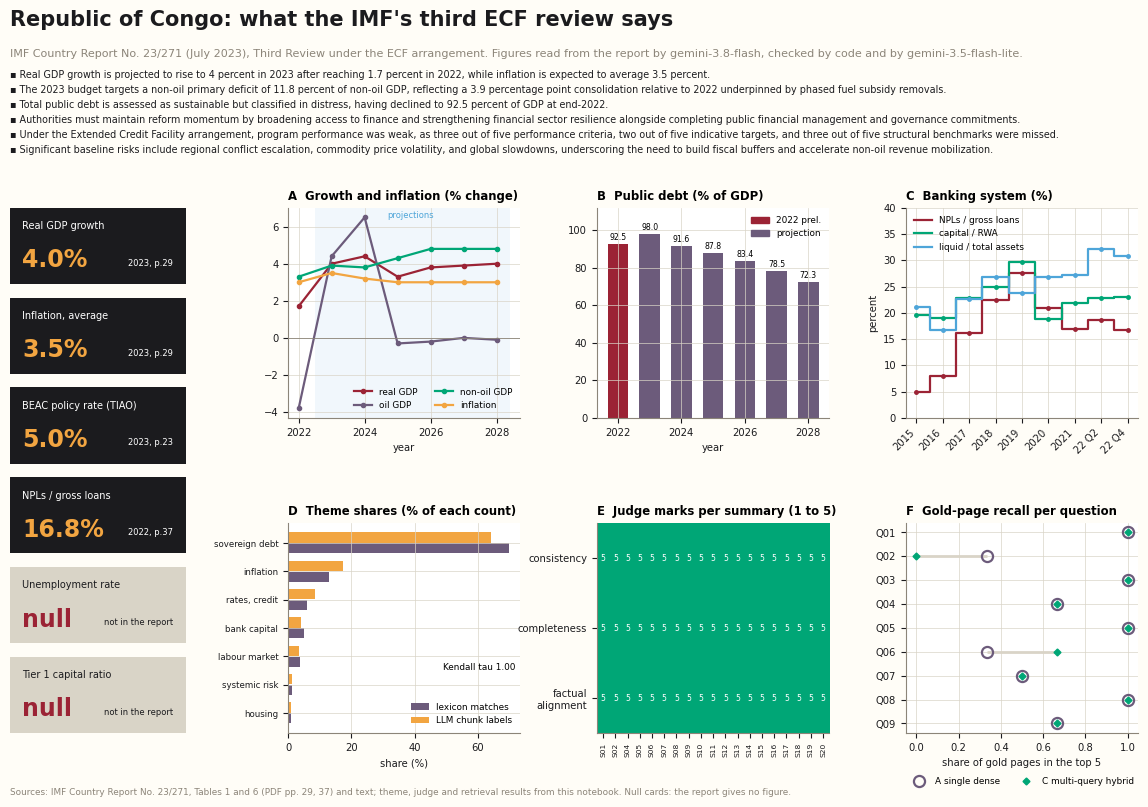

In [28]:
RIVER = {"crimson": "#9B2335", "jade": "#00A676", "gold": "#F2A541", "violet": "#6C5B7B", "sky": "#4EA5D9",
         "charcoal": "#1B1B1E", "ivory": "#FFFDF7", "rule": "#D9D4C7", "mute": "#8C8579"}
plt.rcParams.update({"font.size": 7.2, "axes.titlesize": 8.4, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.edgecolor": RIVER["mute"], "axes.labelcolor": RIVER["charcoal"], "axes.grid": True,
                     "grid.color": RIVER["rule"], "grid.linewidth": 0.5, "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 6.4,
                     "xtick.color": RIVER["charcoal"], "ytick.color": RIVER["charcoal"]})

fig = plt.figure(figsize=(11.69, 8.27), facecolor=RIVER["ivory"])
outer = fig.add_gridspec(1, 2, width_ratios=[0.95, 4.6], left=0.02, right=0.985, top=0.735, bottom=0.1, wspace=0.2)
cards = outer[0].subgridspec(6, 1, hspace=0.18)
panels = outer[1].subgridspec(2, 3, hspace=0.5, wspace=0.33)
fig.text(0.02, 0.955, "Republic of Congo: what the IMF's third ECF review says", fontsize=15, weight="bold", color=RIVER["charcoal"])
fig.text(0.02, 0.918, f"{K.report}. Figures read from the report by {K.writer}, checked by code and by {K.judge}.",
         fontsize=8, color=RIVER["mute"])
for n, b in enumerate(bullets.bullets):   # the executive bullets written and judged in 1.6
    fig.text(0.02, 0.892 - n * 0.018, "\u25aa " + textwrap.shorten(b.text, 215, placeholder=" ..."), fontsize=6.9,
             color=RIVER["charcoal"])

CARD_TEXT = {
    "gdp_growth_forecast_pct": ("Real GDP growth", "%"), "headline_inflation_rate_pct": ("Inflation, average", "%"),
    "central_bank_policy_rate_pct": ("BEAC policy rate (TIAO)", "%"), "non_performing_loan_ratio": ("NPLs / gross loans", "%"),
    "unemployment_rate_pct": ("Unemployment rate", ""), "tier_1_capital_ratio": ("Tier 1 capital ratio", "")}
for n, field in enumerate(INDICATOR_FIELDS):
    ax = fig.add_subplot(cards[n])
    ax.set_axis_off()
    fig_ = getattr(record, field)
    filled = fig_.value is not None
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color=RIVER["charcoal"] if filled else RIVER["rule"]))
    ax.text(0.07, 0.72, CARD_TEXT[field][0], transform=ax.transAxes, color="white" if filled else RIVER["charcoal"], fontsize=7)
    shown = f"{fig_.value:.1f}{CARD_TEXT[field][1]}" if filled else "null"
    ax.text(0.07, 0.22, shown, transform=ax.transAxes, fontsize=17, weight="bold",
            color=RIVER["gold"] if filled else RIVER["crimson"])
    note = f"{fig_.year}, p.{fig_.pdf_page}" if filled else "not in the report"
    ax.text(0.93, 0.24, note, transform=ax.transAxes, ha="right", fontsize=6, color="white" if filled else RIVER["charcoal"])

# A growth and inflation
ax = fig.add_subplot(panels[0, 0])
lines = {"GDP at constant prices": ("real GDP", RIVER["crimson"]), "Oil": ("oil GDP", RIVER["violet"]),
         "Non-oil": ("non-oil GDP", RIVER["jade"]), "Consumer prices (period average)": ("inflation", RIVER["gold"])}
for row, (name, colour) in lines.items():
    d = macro[macro.row == row].sort_values("year")
    ax.plot(d.year, d.value, marker="o", ms=3, lw=1.6, color=colour, label=name)
ax.axvspan(2022.5, 2028.4, color=RIVER["sky"], alpha=0.08, lw=0)
ax.text(2025.4, ax.get_ylim()[1] * 0.92, "projections", ha="center", fontsize=6, color=RIVER["sky"])
ax.axhline(0, color=RIVER["mute"], lw=0.6)
ax.set(title="A  Growth and inflation (% change)", xlabel="year")
ax.legend(ncol=2, loc="lower right")

# B public debt
ax = fig.add_subplot(panels[0, 1])
d = macro[macro.row == "Total public debt (percent of GDP)"].sort_values("year")
bars = ax.bar(d.year, d.value, color=[RIVER["crimson"] if not p else RIVER["violet"] for p in d.projected], width=0.65)
ax.bar_label(bars, fmt="%.1f", fontsize=5.6, padding=1.5)
ax.set(title="B  Public debt (% of GDP)", ylim=(0, 112), xlabel="year")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=RIVER["crimson"]), plt.Rectangle((0, 0), 1, 1, color=RIVER["violet"])],
          labels=["2022 prel.", "projection"], loc="upper right")

# C banks
ax = fig.add_subplot(panels[0, 2])
for row, name, colour in [("Nonperforming loans to total gross loans", "NPLs / gross loans", RIVER["crimson"]),
                          ("Regulatory capital to risk-weighted assets", "capital / RWA", RIVER["jade"]),
                          ("Liquid assets to total assets", "liquid / total assets", RIVER["sky"])]:
    d = banks[banks.row == row]
    ax.step(range(len(d)), d.value, where="mid", lw=1.6, color=colour, label=name)
    ax.plot(range(len(d)), d.value, "o", ms=2.5, color=colour)
ax.set_xticks(range(len(TABLES["Table 6"].columns)), [c.replace("2022 ", "22 ") for c in TABLES["Table 6"].columns],
              rotation=45, ha="right")
ax.set(title="C  Banking system (%)", ylim=(0, 40), ylabel="percent")
ax.legend(loc="upper left")

# D themes
ax = fig.add_subplot(panels[1, 0])
order = themes.sort_values("lexicon_matches").theme.tolist()
y = np.arange(len(order))
for offset, measure, colour, name in [(-0.19, "lexicon", RIVER["violet"], "lexicon matches"),
                                       (0.19, "labels", RIVER["gold"], "LLM chunk labels")]:
    d = theme_long[theme_long.measure == measure].set_index("theme").loc[order]
    ax.barh(y + offset, d.share, height=0.36, color=colour, label=name)
SHORT = {"Inflation & Prices": "inflation", "Interest Rates & Credit": "rates, credit", "Housing & Real Estate": "housing",
         "Banking Capital & Liquidity": "bank capital", "Sovereign Debt": "sovereign debt",
         "Labor Market Dynamics": "labour market", "Systemic Financial Risk": "systemic risk"}
ax.set_yticks(y, [SHORT[t] for t in order], fontsize=6.2)
ax.set(title="D  Theme shares (% of each count)", xlabel="share (%)")
ax.legend(loc="lower right")
ax.text(0.98, 0.3, f"Kendall tau {tau_any.statistic:.2f}", transform=ax.transAxes, ha="right", fontsize=6.4)

# E judge marks
ax = fig.add_subplot(panels[1, 1])
grid = marks.pivot(index="sid", columns="criterion", values="score")[["consistency", "completeness", "factual_alignment"]]
cmap = matplotlib.colors.LinearSegmentedColormap.from_list("river", [RIVER["crimson"], RIVER["gold"], RIVER["jade"]])
ax.imshow(grid.T.values, cmap=cmap, vmin=1, vmax=5, aspect="auto")
for (i, j), v in np.ndenumerate(grid.T.values):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=5.6, color="white")
ax.set_yticks(range(3), ["consistency", "completeness", "factual\nalignment"])
ax.set_xticks(range(len(grid)), grid.index, rotation=90, fontsize=5.4)
ax.grid(False)
ax.set(title="E  Judge marks per summary (1 to 5)")

# F retrieval
ax = fig.add_subplot(panels[1, 2])
d = ext[ext.qid != "Q10"].reset_index(drop=True)
ax.hlines(d.index, d.A_gold_recall, d.C_gold_recall, color=RIVER["rule"], lw=2)
ax.plot(d.A_gold_recall, d.index, "o", ms=8, mfc="none", mew=1.6, color=RIVER["violet"], label="A single dense")   # hollow, so a tie still shows both
ax.plot(d.C_gold_recall, d.index, "D", ms=3.5, color=RIVER["jade"], label="C multi-query hybrid")
ax.set_yticks(d.index, d.qid)
ax.invert_yaxis()
ax.set(title="F  Gold-page recall per question", xlabel="share of gold pages in the top 5", xlim=(-0.05, 1.05))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)

fig.text(0.02, 0.025, "Sources: IMF Country Report No. 23/271, Tables 1 and 6 (PDF pp. 29, 37) and text; theme, judge and "
         "retrieval results from this notebook. Null cards: the report gives no figure.", fontsize=6.4, color=RIVER["mute"])
fig.savefig(K.results / "dashboard.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

**Extension chart**

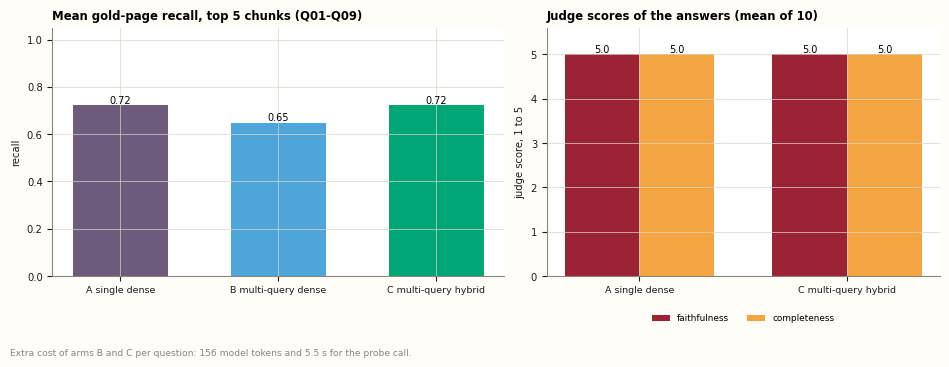

In [29]:
fig, (left, right) = plt.subplots(1, 2, figsize=(9.5, 3.6), facecolor=RIVER["ivory"], gridspec_kw={"width_ratios": [1.15, 1]})
arms = compare.arm.tolist()
colours = [RIVER["violet"], RIVER["sky"], RIVER["jade"]]
bars = left.bar(arms, compare["mean gold recall"], color=colours, width=0.6)
left.bar_label(bars, fmt="%.2f", fontsize=7)
left.set(title="Mean gold-page recall, top 5 chunks (Q01-Q09)", ylim=(0, 1.05), ylabel="recall")
left.tick_params(axis="x", labelsize=6.8)
judged = compare.dropna(subset=["judge faithfulness (10)"])
x = np.arange(len(judged))
right.bar(x - 0.18, judged["judge faithfulness (10)"], width=0.36, color=RIVER["crimson"], label="faithfulness")
right.bar(x + 0.18, judged["judge completeness (10)"], width=0.36, color=RIVER["gold"], label="completeness")
right.set_xticks(x, judged.arm, fontsize=6.8)
right.set(title="Judge scores of the answers (mean of 10)", ylim=(0, 5.6), ylabel="judge score, 1 to 5")
for bar_set in right.containers:
    right.bar_label(bar_set, fmt="%.1f", fontsize=7)
right.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12))
fig.text(0.01, 0.01, f"Extra cost of arms B and C per question: {compare.iloc[1]['extra model tokens per question']:.0f} model "
         f"tokens and {compare.iloc[1]['extra model seconds per question']:.1f} s for the probe call.", fontsize=6.6,
         color=RIVER["mute"])
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(K.results / "extension.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

**Part 6. Run record**

This saves the model calls, the prompts and the hand checks.

In [30]:
log = pd.DataFrame(CALLS)
keep("call_log", {"backend": BACKEND, "writer": K.writer, "judge": K.judge, "calls": len(log),
                  "live": int((log.origin == "live").sum()), "stored": int((log.origin == "stored").sum()),
                  "repairs": int(log.repair.sum()), "rows": log})
keep("prompt_book", {name: attrs.asdict(card) for name, card in CARDS.items()})
print(f"backend {BACKEND}: {len(log)} calls ({int((log.origin == 'live').sum())} live, "
      f"{int((log.origin == 'stored').sum())} stored), {int(log.repair.sum())} repair rounds")
log.groupby(["role", "model"]).agg(calls=("step", "size"), live=("origin", lambda s: int((s == "live").sum())),
                                   mean_seconds=("seconds", "mean"), tokens_in=("tokens_in", "sum"),
                                   tokens_out=("tokens_out", "sum")).round(2)

backend gemini_api: 116 calls (0 live, 116 stored), 0 repair rounds


,,calls,live,mean_seconds,tokens_in,tokens_out
role,model,,,,,
judge,gemini-3.5-flash-lite,43,0,0.87,194747,4275
writer,gemini-3.8-flash,73,0,15.43,345230,18073


**Where each hand value was read**

In [31]:
hand_rows = []
for field, (value, year, page, where, again) in HAND.items():
    if page is None:
        line = where
    elif where.startswith("text"):
        line = textwrap.shorten(next(s for s in re.split(r"(?<=\.)\s+", " ".join(LEAVES[page - 1].clean.split()))
                                     if "TIAO" in s), 200)
    else:
        row_label = where.split(", ")[1]
        line = next(l.strip() for l in LEAVES[page - 1].clean.split("\n") if l.strip().startswith(row_label))
    hand_rows.append({"field": field, "hand_value": value, "year": year, "pdf_page": page, "printed": line,
                      "pipeline_value": INDICATORS[field], "agrees": INDICATORS[field] == value})
hand = pd.DataFrame(hand_rows)
keep("hand_checks", hand)
for r in hand.itertuples():
    where_ = "no page" if pd.isna(r.pdf_page) else f"p.{int(r.pdf_page)}"
    shown = ["null" if pd.isna(v) else v for v in (r.hand_value, r.pipeline_value)]
    print(f"{r.field}: hand {shown[0]} | pipeline {shown[1]} | {where_}: {r.printed}")

gdp_growth_forecast_pct: hand 4.0 | pipeline 4.0 | p.29: GDP at constant prices 2.8 1.7 4.1 4.0 4.4 3.3 3.8 3.9 4.0
headline_inflation_rate_pct: hand 3.5 | pipeline 3.5 | p.29: Consumer prices (period average) 3.5 3.0 3.3 3.5 3.2 3.0 3.0 3.0 3.0
central_bank_policy_rate_pct: hand 5.0 | pipeline 5.0 | p.23: In 2023, BEAC raised its main policy rate (TIAO) by 50 basis points to 5 percent in March 2023 —a cumulative 175 basis points increase since November 2021, and tightened banks’ refinancing [...]
non_performing_loan_ratio: hand 16.8 | pipeline 16.8 | p.37: Nonperforming loans to total gross loans 5.0 8.0 16.2 22.5 27.5 21.0 16.9 18.6 16.8
unemployment_rate_pct: hand null | pipeline null | no page: no figure in the report; p.49 says only that it is among the world's highest
tier_1_capital_ratio: hand null | pipeline null | no page: not reported; Table 6 gives total regulatory capital to risk-weighted assets only


**Files written by this run**

In [32]:
REPLIES.close()
for f in sorted(K.results.glob("*")):
    print(f"{f.name:40} {f.stat().st_size / 1024:8.1f} KB")

call_log.json                                25.6 KB
chunks.json                                 452.9 KB
dashboard.png                               733.7 KB
executive_summary.json                        6.3 KB
extension.png                               111.0 KB
extension_multiquery_hybrid.json             20.0 KB
hand_checks.json                              1.6 KB
indicators.json                               0.2 KB
indicators_provenance.json                    5.5 KB
prompt_book.json                              7.1 KB
rag_answers.json                             13.5 KB
section_summaries.json                       29.6 KB
sections.json                                 3.3 KB
strengths_vulnerabilities.json                8.2 KB
theme_counts.json                            29.3 KB
time_series.json                             21.2 KB
